In [179]:
import pandas as pd
import numpy as np

credit_fe = pd.read_csv("../Data/Processed/credit_feature_engineered.csv")

credit_fe.shape

(149999, 21)

In [180]:
credit_fe["SeriousDlqin2yrs"].value_counts()

SeriousDlqin2yrs
0    139973
1     10026
Name: count, dtype: int64

In [181]:
credit_fe["SeriousDlqin2yrs"].value_counts(normalize=True) * 100

SeriousDlqin2yrs
0    93.315955
1     6.684045
Name: proportion, dtype: float64

In [182]:
X = credit_fe.drop(columns=["SeriousDlqin2yrs"])
y = credit_fe["SeriousDlqin2yrs"]

In [183]:
print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (149999, 20)
y shape: (149999,)


In [184]:
X.dtypes

RevolvingUtilizationOfUnsecuredLines    float64
age                                       int64
NumberOfTime30-59DaysPastDueNotWorse    float64
DebtRatio                               float64
MonthlyIncome                           float64
NumberOfOpenCreditLinesAndLoans           int64
NumberOfTimes90DaysLate                 float64
NumberRealEstateLoansOrLines              int64
NumberOfTime60-89DaysPastDueNotWorse    float64
NumberOfDependents                      float64
TotalDelinquency                        float64
HasDelinquency                            int64
HasSevereDelinquency                      int64
LogCreditUtilization                    float64
HighCreditUtilization                     int64
LogMonthlyIncome                        float64
IncomeCategory                              str
LogDebtRatio                            float64
HighDebtRatio                             int64
TotalCreditAccounts                       int64
dtype: object

In [185]:
modeling_df=credit_fe.copy()

## Train-Test Split

The dataset has a significant class imbalance, with default cases representing approximately 6.68% of observations.

A stratified train-test split is therefore used to preserve approximately the same target-class distribution in both training and testing datasets.

In [186]:
X = modeling_df.drop("SeriousDlqin2yrs", axis=1)
y = modeling_df["SeriousDlqin2yrs"]

In [187]:
X.shape, y.shape

((149999, 20), (149999,))

## Modeling Dataset Checkpoint

Feature engineering and preprocessing have been completed.

The resulting dataset contains the cleaned original features along with engineered features designed to capture delinquency behavior, credit utilization, income characteristics, debt burden, and overall credit exposure.

The modeling stage will use a stratified train-test split followed by Stratified K-Fold Cross-Validation on the training data. The test set will remain untouched until final model evaluation.

In [188]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=42
)

In [189]:
print("Training set:", X_train.shape)
print("Test set:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True))

print("\nTest target distribution:")
print(y_test.value_counts(normalize=True))

Training set: (119999, 20)
Test set: (30000, 20)

Training target distribution:
SeriousDlqin2yrs
0    0.933158
1    0.066842
Name: proportion, dtype: float64

Test target distribution:
SeriousDlqin2yrs
0    0.933167
1    0.066833
Name: proportion, dtype: float64


In [190]:
numeric_features = X_train.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["str","object", "category"]
).columns.tolist()

print("Numerical features:", len(numeric_features))
print("Categorical features:", categorical_features)

Numerical features: 19
Categorical features: ['IncomeCategory']


In [191]:
from sklearn.model_selection import StratifiedKFold

skf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

## Modeling Preprocessing Pipeline

Numerical features are standardized using `StandardScaler`, while categorical features are converted into numerical representations using `OneHotEncoder`.

All preprocessing transformations are fitted only on the training data through a scikit-learn pipeline to prevent data leakage.

In [192]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

In [193]:
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

In [194]:
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    ))
])

In [195]:
preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features)
])

## Baseline Logistic Regression

Logistic Regression is used as the baseline classification model.

It provides a simple and interpretable benchmark against which more complex models can be compared.

The model will be evaluated using Stratified 5-Fold Cross-Validation on the training set. Since this is the baseline model, no class weighting is applied.

The test set will remain untouched until final model evaluation.

In [196]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

logistic_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

In [197]:
scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc",
    "pr_auc": "average_precision"
}

In [198]:
from sklearn.model_selection import cross_validate

logistic_cv = cross_validate(
    logistic_pipeline,
    X_train,
    y_train,
    cv=skf,
    scoring=scoring,
    n_jobs=-1
)

In [199]:
logistic_results = {
    "Model": "Baseline Logistic",
    
    "Accuracy": logistic_cv["test_accuracy"].mean(),
    "Precision": logistic_cv["test_precision"].mean(),
    "Recall": logistic_cv["test_recall"].mean(),
    "F1": logistic_cv["test_f1"].mean(),
    "ROC-AUC": logistic_cv["test_roc_auc"].mean(),
    "PR-AUC": logistic_cv["test_pr_auc"].mean(),
    
    "Accuracy_STD": logistic_cv["test_accuracy"].std(),
    "Precision_STD": logistic_cv["test_precision"].std(),
    "Recall_STD": logistic_cv["test_recall"].std(),
    "F1_STD": logistic_cv["test_f1"].std(),
    "ROC-AUC_STD": logistic_cv["test_roc_auc"].std(),
    "PR-AUC_STD": logistic_cv["test_pr_auc"].std()
}

pd.DataFrame([logistic_results]).round(4)

,Model,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC,Accuracy_STD,Precision_STD,Recall_STD,F1_STD,ROC-AUC_STD,PR-AUC_STD
0,Baseline Logistic,0.9368,0.5986,0.1641,0.2575,0.8535,0.3696,0.0006,0.015,0.0094,0.0127,0.0064,0.0067


In [200]:
pd.DataFrame({
    "Fold": range(1, 6),
    "Accuracy": logistic_cv["test_accuracy"],
    "Precision": logistic_cv["test_precision"],
    "Recall": logistic_cv["test_recall"],
    "F1": logistic_cv["test_f1"],
    "ROC-AUC": logistic_cv["test_roc_auc"],
    "PR-AUC": logistic_cv["test_pr_auc"]
}).round(4)

,Fold,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
0,1,0.9365,0.5939,0.1577,0.2493,0.8505,0.3688
1,2,0.9358,0.5737,0.1552,0.2444,0.8437,0.3582
2,3,0.9375,0.6121,0.1771,0.2747,0.8602,0.3782
3,4,0.9375,0.6159,0.1738,0.2711,0.8523,0.3739
4,5,0.9366,0.5976,0.1565,0.2480,0.8609,0.3691


## Balanced Logistic Regression

The baseline Logistic Regression may be biased toward the majority non-default class because approximately 93% of observations belong to class 0.

To address this imbalance, a second Logistic Regression model is trained using `class_weight="balanced"`.

The balanced model assigns higher importance to the minority default class during training. Stratified 5-Fold Cross-Validation is used to compare its performance fairly with the baseline model.

In [201]:
balanced_logistic_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    ))
])

In [202]:
balanced_logistic_cv = cross_validate(
    balanced_logistic_pipeline,
    X_train,
    y_train,
    cv=skf,
    scoring=scoring,
    n_jobs=-1
)

In [203]:
balanced_logistic_results = {
    "Model": "Balanced Logistic",
    
    "Accuracy": balanced_logistic_cv["test_accuracy"].mean(),
    "Precision": balanced_logistic_cv["test_precision"].mean(),
    "Recall": balanced_logistic_cv["test_recall"].mean(),
    "F1": balanced_logistic_cv["test_f1"].mean(),
    "ROC-AUC": balanced_logistic_cv["test_roc_auc"].mean(),
    "PR-AUC": balanced_logistic_cv["test_pr_auc"].mean(),
    
    "Accuracy_STD": balanced_logistic_cv["test_accuracy"].std(),
    "Precision_STD": balanced_logistic_cv["test_precision"].std(),
    "Recall_STD": balanced_logistic_cv["test_recall"].std(),
    "F1_STD": balanced_logistic_cv["test_f1"].std(),
    "ROC-AUC_STD": balanced_logistic_cv["test_roc_auc"].std(),
    "PR-AUC_STD": balanced_logistic_cv["test_pr_auc"].std()
}

pd.DataFrame([balanced_logistic_results]).round(4)

,Model,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC,Accuracy_STD,Precision_STD,Recall_STD,F1_STD,ROC-AUC_STD,PR-AUC_STD
0,Balanced Logistic,0.8084,0.2207,0.7369,0.3396,0.856,0.357,0.0016,0.0029,0.0145,0.0048,0.0063,0.0079


In [204]:
pd.DataFrame({
    "Fold": range(1, 6),
    "Accuracy": balanced_logistic_cv["test_accuracy"],
    "Precision": balanced_logistic_cv["test_precision"],
    "Recall": balanced_logistic_cv["test_recall"],
    "F1": balanced_logistic_cv["test_f1"],
    "ROC-AUC": balanced_logistic_cv["test_roc_auc"],
    "PR-AUC": balanced_logistic_cv["test_pr_auc"]
}).round(4)

,Fold,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
0,1,0.8108,0.2226,0.7344,0.3416,0.8537,0.3586
1,2,0.8070,0.2153,0.7138,0.3308,0.8457,0.3471
2,3,0.8075,0.2234,0.7594,0.3452,0.8623,0.3667
3,4,0.8070,0.2200,0.7408,0.3393,0.8552,0.3639
4,5,0.8100,0.2220,0.7363,0.3412,0.8629,0.3487


In [205]:
logistic_comparison = pd.DataFrame([
    logistic_results,
    balanced_logistic_results
])

logistic_comparison.round(4)

,Model,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC,Accuracy_STD,Precision_STD,Recall_STD,F1_STD,ROC-AUC_STD,PR-AUC_STD
0,Baseline Logistic,0.9368,0.5986,0.1641,0.2575,0.8535,0.3696,0.0006,0.0150,0.0094,0.0127,0.0064,0.0067
1,Balanced Logistic,0.8084,0.2207,0.7369,0.3396,0.8560,0.3570,0.0016,0.0029,0.0145,0.0048,0.0063,0.0079


## Random Forest

Random Forest is introduced to capture nonlinear relationships and interactions between features that Logistic Regression may not capture.

The model consists of multiple decision trees whose predictions are aggregated to produce the final prediction.

Since the target variable is highly imbalanced, class weighting is used to give greater importance to the minority default class.

The model will be evaluated using Stratified 5-Fold Cross-Validation.

In [206]:
from sklearn.ensemble import RandomForestClassifier

rf_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestClassifier(
        n_estimators=300,
        max_depth=None,
        min_samples_split=10,
        min_samples_leaf=5,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

In [207]:
rf_cv = cross_validate(
    rf_pipeline,
    X_train,
    y_train,
    cv=skf,
    scoring=scoring,
    n_jobs=-1
)

In [208]:
rf_results = {
    "Model": "Random Forest",
    
    "Accuracy": rf_cv["test_accuracy"].mean(),
    "Precision": rf_cv["test_precision"].mean(),
    "Recall": rf_cv["test_recall"].mean(),
    "F1": rf_cv["test_f1"].mean(),
    "ROC-AUC": rf_cv["test_roc_auc"].mean(),
    "PR-AUC": rf_cv["test_pr_auc"].mean(),
    
    "Accuracy_STD": rf_cv["test_accuracy"].std(),
    "Precision_STD": rf_cv["test_precision"].std(),
    "Recall_STD": rf_cv["test_recall"].std(),
    "F1_STD": rf_cv["test_f1"].std(),
    "ROC-AUC_STD": rf_cv["test_roc_auc"].std(),
    "PR-AUC_STD": rf_cv["test_pr_auc"].std()
}

pd.DataFrame([rf_results]).round(4)

,Model,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC,Accuracy_STD,Precision_STD,Recall_STD,F1_STD,ROC-AUC_STD,PR-AUC_STD
0,Random Forest,0.876,0.2962,0.6212,0.4012,0.8537,0.3779,0.0014,0.0057,0.0148,0.0083,0.0058,0.0079


In [209]:
pd.DataFrame({
    "Fold": range(1, 6),
    "Accuracy": rf_cv["test_accuracy"],
    "Precision": rf_cv["test_precision"],
    "Recall": rf_cv["test_recall"],
    "F1": rf_cv["test_f1"],
    "ROC-AUC": rf_cv["test_roc_auc"],
    "PR-AUC": rf_cv["test_pr_auc"]
}).round(4)

,Fold,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
0,1,0.8758,0.2945,0.6153,0.3983,0.8496,0.3817
1,2,0.8743,0.2884,0.6004,0.3896,0.8453,0.3651
2,3,0.8775,0.3034,0.6421,0.4121,0.8579,0.3895
3,4,0.8748,0.2926,0.6150,0.3965,0.8542,0.3768
4,5,0.8777,0.3022,0.6334,0.4092,0.8616,0.3763


In [210]:
model_cv_results = pd.DataFrame([
    logistic_results,
    balanced_logistic_results,
    rf_results
])

model_cv_results.round(4)

,Model,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC,Accuracy_STD,Precision_STD,Recall_STD,F1_STD,ROC-AUC_STD,PR-AUC_STD
0,Baseline Logistic,0.9368,0.5986,0.1641,0.2575,0.8535,0.3696,0.0006,0.0150,0.0094,0.0127,0.0064,0.0067
1,Balanced Logistic,0.8084,0.2207,0.7369,0.3396,0.8560,0.3570,0.0016,0.0029,0.0145,0.0048,0.0063,0.0079
2,Random Forest,0.8760,0.2962,0.6212,0.4012,0.8537,0.3779,0.0014,0.0057,0.0148,0.0083,0.0058,0.0079


## XGBoost

XGBoost is introduced as a gradient boosting model capable of learning complex nonlinear relationships and interactions between features.

Unlike Random Forest, where trees are built independently, XGBoost builds trees sequentially, with each tree attempting to correct errors made by previous trees.

Class imbalance is addressed using `scale_pos_weight`.

The model will be evaluated using Stratified 5-Fold Cross-Validation using the same metrics as the other candidate models.

In [211]:
scale_pos_weight = (
    (y_train == 0).sum() /
    (y_train == 1).sum()
)

print("Scale Pos Weight:", scale_pos_weight)

Scale Pos Weight: 13.960603416032914


In [ ]:
from xgboost import XGBClassifier

xgb_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", XGBClassifier(
        n_estimators=300,
        max_depth=5,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        scale_pos_weight=scale_pos_weight,
        objective="binary:logistic",
        eval_metric="logloss",
        random_state=42,
        n_jobs=-1
    ))
])

In [213]:
xgb_cv = cross_validate(
    xgb_pipeline,
    X_train,
    y_train,
    cv=skf,
    scoring=scoring,
    n_jobs=-1
)

In [214]:
xgb_results = {
    "Model": "XGBoost",
    
    "Accuracy": xgb_cv["test_accuracy"].mean(),
    "Precision": xgb_cv["test_precision"].mean(),
    "Recall": xgb_cv["test_recall"].mean(),
    "F1": xgb_cv["test_f1"].mean(),
    "ROC-AUC": xgb_cv["test_roc_auc"].mean(),
    "PR-AUC": xgb_cv["test_pr_auc"].mean(),
    
    "Accuracy_STD": xgb_cv["test_accuracy"].std(),
    "Precision_STD": xgb_cv["test_precision"].std(),
    "Recall_STD": xgb_cv["test_recall"].std(),
    "F1_STD": xgb_cv["test_f1"].std(),
    "ROC-AUC_STD": xgb_cv["test_roc_auc"].std(),
    "PR-AUC_STD": xgb_cv["test_pr_auc"].std()
}

pd.DataFrame([xgb_results]).round(4)

,Model,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC,Accuracy_STD,Precision_STD,Recall_STD,F1_STD,ROC-AUC_STD,PR-AUC_STD
0,XGBoost,0.8072,0.2221,0.7524,0.3429,0.8619,0.3933,0.0034,0.0051,0.016,0.0075,0.0059,0.0073


In [215]:
pd.DataFrame({
    "Fold": range(1, 6),
    "Accuracy": xgb_cv["test_accuracy"],
    "Precision": xgb_cv["test_precision"],
    "Recall": xgb_cv["test_recall"],
    "F1": xgb_cv["test_f1"],
    "ROC-AUC": xgb_cv["test_roc_auc"],
    "PR-AUC": xgb_cv["test_pr_auc"]
}).round(4)

,Fold,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
0,1,0.8083,0.2209,0.7394,0.3402,0.8592,0.3921
1,2,0.8018,0.2129,0.7288,0.3296,0.8528,0.3877
2,3,0.8050,0.2230,0.7718,0.3460,0.8665,0.4076
3,4,0.8097,0.2266,0.7645,0.3495,0.8613,0.3897
4,5,0.8113,0.2269,0.7575,0.3492,0.8698,0.3895


In [216]:
model_cv_results = pd.DataFrame([
    logistic_results,
    balanced_logistic_results,
    rf_results,
    xgb_results
])

model_cv_results.round(4)

,Model,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC,Accuracy_STD,Precision_STD,Recall_STD,F1_STD,ROC-AUC_STD,PR-AUC_STD
0,Baseline Logistic,0.9368,0.5986,0.1641,0.2575,0.8535,0.3696,0.0006,0.0150,0.0094,0.0127,0.0064,0.0067
1,Balanced Logistic,0.8084,0.2207,0.7369,0.3396,0.8560,0.3570,0.0016,0.0029,0.0145,0.0048,0.0063,0.0079
2,Random Forest,0.8760,0.2962,0.6212,0.4012,0.8537,0.3779,0.0014,0.0057,0.0148,0.0083,0.0058,0.0079
3,XGBoost,0.8072,0.2221,0.7524,0.3429,0.8619,0.3933,0.0034,0.0051,0.0160,0.0075,0.0059,0.0073


In [217]:

model_cv_results[
    [
        "Model",
        "Recall",
        "Recall_STD",
        "Precision",
        "F1",
        "ROC-AUC",
        "PR-AUC"
    ]
].round(4)

,Model,Recall,Recall_STD,Precision,F1,ROC-AUC,PR-AUC
0,Baseline Logistic,0.1641,0.0094,0.5986,0.2575,0.8535,0.3696
1,Balanced Logistic,0.7369,0.0145,0.2207,0.3396,0.8560,0.3570
2,Random Forest,0.6212,0.0148,0.2962,0.4012,0.8537,0.3779
3,XGBoost,0.7524,0.0160,0.2221,0.3429,0.8619,0.3933


### Cross-Validation Model Selection

Stratified 5-Fold Cross-Validation was performed on the training dataset to obtain a reliable comparison of the candidate models.

XGBoost achieved the highest recall (75.24%), ROC-AUC (0.8619), and PR-AUC (0.3933) among the evaluated models. Random Forest achieved the highest F1-score (0.4012), while Baseline Logistic Regression achieved the highest precision but substantially lower recall.

Since the primary business objective is to minimize false negatives and identify potential defaulters, recall is prioritized over accuracy and precision. Based on the cross-validation results, XGBoost is selected as the leading candidate for further threshold optimization.

However, the classification threshold of 0.5 is not assumed to be optimal. Out-of-fold probability predictions will be used to perform threshold optimization without using the final test set.

## Out-of-Fold Predictions for Threshold Optimization

To optimize the classification threshold without introducing test-set leakage, out-of-fold probability predictions are generated from the training data.

Each observation receives a prediction from a model that was not trained on that observation. These out-of-fold probabilities provide an unbiased estimate of model predictions on unseen training observations.

These predictions will be used to select a suitable classification threshold based on the business objective of minimizing false negatives.

In [218]:
from sklearn.model_selection import cross_val_predict

In [219]:
oof_predictions = {}

oof_predictions["Baseline Logistic"] = cross_val_predict(
    logistic_pipeline,
    X_train,
    y_train,
    cv=skf,
    method="predict_proba",
    n_jobs=-1
)[:, 1]

oof_predictions["Balanced Logistic"] = cross_val_predict(
    balanced_logistic_pipeline,
    X_train,
    y_train,
    cv=skf,
    method="predict_proba",
    n_jobs=-1
)[:, 1]

oof_predictions["Random Forest"] = cross_val_predict(
    rf_pipeline,
    X_train,
    y_train,
    cv=skf,
    method="predict_proba",
    n_jobs=-1
)[:, 1]

oof_predictions["XGBoost"] = cross_val_predict(
    xgb_pipeline,
    X_train,
    y_train,
    cv=skf,
    method="predict_proba",
    n_jobs=-1
)[:, 1]

In [220]:
for model_name, probabilities in oof_predictions.items():
    print(
        model_name,
        "→",
        len(probabilities),
        "predictions",
        "| Min:", round(probabilities.min(), 4),
        "| Max:", round(probabilities.max(), 4)
    )

Baseline Logistic → 119999 predictions | Min: 0.0 | Max: 0.9994
Balanced Logistic → 119999 predictions | Min: 0.0 | Max: 1.0
Random Forest → 119999 predictions | Min: 0.0 | Max: 0.9933
XGBoost → 119999 predictions | Min: 0.0042 | Max: 0.9889


## Threshold Optimization Using Out-of-Fold Predictions

The default classification threshold of 0.50 is not necessarily optimal for credit-risk prediction.

Since false negatives represent potentially risky borrowers being classified as non-defaulters, the threshold will be evaluated with greater emphasis on recall.

Thresholds will be compared using recall, precision, F1-score, false positives, and false negatives.

The final threshold will be selected according to the business requirement rather than accuracy alone.

In [221]:
import numpy as np
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

def evaluate_thresholds(y_true, probabilities, model_name):

    thresholds = np.arange(0.10, 0.51, 0.05)

    results = []

    for threshold in thresholds:

        predictions = (probabilities >= threshold).astype(int)

        tn, fp, fn, tp = confusion_matrix(
            y_true,
            predictions
        ).ravel()

        results.append({
            "Model": model_name,
            "Threshold": round(threshold, 2),
            "Accuracy": accuracy_score(y_true, predictions),
            "Precision": precision_score(
                y_true,
                predictions,
                zero_division=0
            ),
            "Recall": recall_score(
                y_true,
                predictions,
                zero_division=0
            ),
            "F1": f1_score(
                y_true,
                predictions,
                zero_division=0
            ),
            "False_Positives": fp,
            "False_Negatives": fn,
            "True_Positives": tp,
            "True_Negatives": tn
        })

    return pd.DataFrame(results)

In [222]:
threshold_results = []

for model_name, probabilities in oof_predictions.items():

    result = evaluate_thresholds(
        y_train,
        probabilities,
        model_name
    )

    threshold_results.append(result)

threshold_results = pd.concat(
    threshold_results,
    ignore_index=True
)

threshold_results.round(4)

,Model,Threshold,Accuracy,Precision,Recall,F1,False_Positives,False_Negatives,True_Positives,True_Negatives
0,Baseline Logistic,0.10,0.8688,0.2806,0.6159,0.3855,12667,3081,4940,99311
1,Baseline Logistic,0.15,0.9000,0.3430,0.5408,0.4197,8311,3683,4338,103667
2,Baseline Logistic,0.20,0.9158,0.3914,0.4673,0.4260,5828,4273,3748,106150
3,Baseline Logistic,0.25,0.9254,0.4364,0.3992,0.4170,4136,4819,3202,107842
4,Baseline Logistic,0.30,0.9301,0.4687,0.3411,0.3949,3101,5285,2736,108877
5,Baseline Logistic,0.35,0.9334,0.5028,0.2934,0.3705,2327,5668,2353,109651
6,Baseline Logistic,0.40,0.9352,0.5343,0.2421,0.3332,1693,6079,1942,110285
7,Baseline Logistic,0.45,0.9363,0.5667,0.1976,0.2930,1212,6436,1585,110766
8,Baseline Logistic,0.50,0.9368,0.5990,0.1641,0.2576,881,6705,1316,111097
9,Balanced Logistic,0.10,0.1341,0.0713,0.9946,0.1331,103865,43,7978,8113


In [223]:
high_recall_results = threshold_results[
    threshold_results["Recall"] >= 0.80
].copy()

high_recall_results[
    [
        "Model",
        "Threshold",
        "Recall",
        "Precision",
        "F1",
        "False_Positives",
        "False_Negatives"
    ]
].sort_values(
    ["Recall", "Precision"],
    ascending=[False, False]
).round(4)

,Model,Threshold,Recall,Precision,F1,False_Positives,False_Negatives
9,Balanced Logistic,0.10,0.9946,0.0713,0.1331,103865,43
10,Balanced Logistic,0.15,0.9757,0.0872,0.1601,81945,195
27,XGBoost,0.10,0.9742,0.0898,0.1644,79198,207
28,XGBoost,0.15,0.9516,0.1070,0.1923,63720,388
11,Balanced Logistic,0.20,0.9478,0.1062,0.1909,64003,419
18,Random Forest,0.10,0.9293,0.1119,0.1997,59169,567
29,XGBoost,0.20,0.9257,0.1229,0.2170,53002,596
12,Balanced Logistic,0.25,0.9222,0.1249,0.2200,51825,624
30,XGBoost,0.25,0.8994,0.1372,0.2381,45357,807
13,Balanced Logistic,0.30,0.8961,0.1415,0.2444,43606,833


## Business-Oriented Threshold Selection

Since the primary objective of the credit-risk system is to identify potential defaulters and minimize false negatives, recall is prioritized during threshold selection.

However, maximizing recall alone would result in an excessive number of false-positive predictions. Therefore, a minimum recall requirement of 80% is used as the initial business constraint.

Among the candidate models satisfying this requirement, XGBoost at a threshold of 0.40 provides the strongest overall trade-off, achieving approximately 82.31% recall, 18.34% precision, and an F1-score of 30.00%.

At this threshold, the model produces 1,419 false negatives and 29,392 false positives on the out-of-fold training predictions.

Therefore, XGBoost with a classification threshold of 0.40 is selected as the candidate configuration for final evaluation on the previously untouched test set.

## Final Model Training and Test Evaluation

Based on Stratified 5-Fold Cross-Validation and out-of-fold threshold optimization, XGBoost was selected as the final candidate model.

A classification threshold of 0.40 was selected using the training data because it achieved more than 80% recall while maintaining a better precision-F1 trade-off than the other candidate models at comparable recall levels.

The selected XGBoost model is now retrained on the complete training dataset and evaluated once on the previously untouched test set.

The test set is not used for model selection or threshold optimization.

In [224]:
xgb_pipeline.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](20,)","['RevolvingUtilizationOfUnsecuredLines','age', 'NumberOfTime30-59DaysPastDueNotWorse',...,'LogDebtRatio','HighDebtRatio', 'TotalCreditAccounts']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,20
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped

In [225]:
test_probabilities = xgb_pipeline.predict_proba(X_test)[:, 1]

In [226]:
final_threshold = 0.40

y_test_pred = (
    test_probabilities >= final_threshold
).astype(int)

In [227]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

final_accuracy = accuracy_score(y_test, y_test_pred)
final_precision = precision_score(y_test, y_test_pred)
final_recall = recall_score(y_test, y_test_pred)
final_f1 = f1_score(y_test, y_test_pred)

final_roc_auc = roc_auc_score(
    y_test,
    test_probabilities
)

final_pr_auc = average_precision_score(
    y_test,
    test_probabilities
)

final_results = pd.DataFrame([{
    "Model": "Final XGBoost",
    "Threshold": final_threshold,
    "Accuracy": final_accuracy,
    "Precision": final_precision,
    "Recall": final_recall,
    "F1": final_f1,
    "ROC-AUC": final_roc_auc,
    "PR-AUC": final_pr_auc
}])

final_results.round(4)

,Model,Threshold,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
0,Final XGBoost,0.4,0.7425,0.1849,0.8374,0.303,0.8676,0.3901


In [228]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(
    y_test,
    y_test_pred
)

cm

array([[20595,  7400],
       [  326,  1679]])

In [229]:
tn, fp, fn, tp = cm.ravel()

print("True Negatives :", tn)
print("False Positives:", fp)
print("False Negatives:", fn)
print("True Positives :", tp)

True Negatives : 20595
False Positives: 7400
False Negatives: 326
True Positives : 1679


In [230]:
fn_rate = fn / (fn + tp)

print("False Negative Rate:", round(fn_rate, 4))
print("False Negative Rate (%):", round(fn_rate * 100, 2))

False Negative Rate: 0.1626
False Negative Rate (%): 16.26


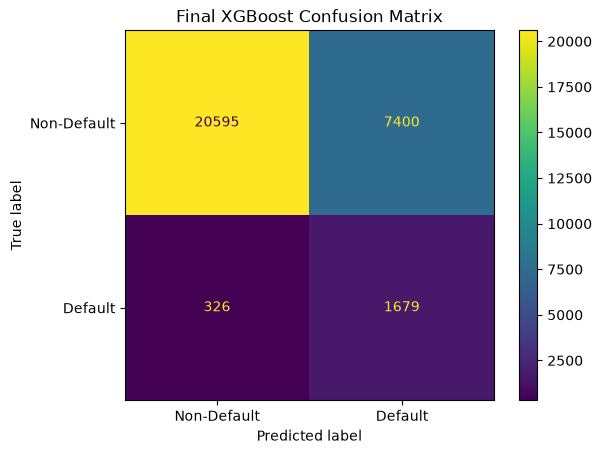

In [231]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Non-Default", "Default"]
).plot()

plt.title("Final XGBoost Confusion Matrix")
plt.show()

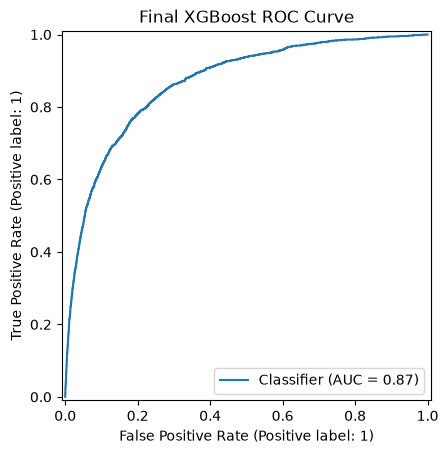

In [232]:
from sklearn.metrics import RocCurveDisplay

RocCurveDisplay.from_predictions(
    y_test,
    test_probabilities
)

plt.title("Final XGBoost ROC Curve")
plt.show()

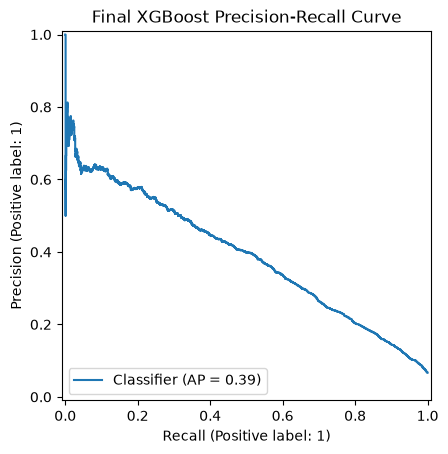

In [233]:
from sklearn.metrics import PrecisionRecallDisplay

PrecisionRecallDisplay.from_predictions(
    y_test,
    test_probabilities
)

plt.title("Final XGBoost Precision-Recall Curve")
plt.show()

## Final Model Evaluation

XGBoost was selected as the final model based on Stratified 5-Fold Cross-Validation and out-of-fold threshold optimization. A classification threshold of 0.40 was selected to prioritize recall while maintaining a reasonable trade-off between false negatives and false positives.

When retrained on the complete training dataset and evaluated on the untouched test set, the model achieved a recall of 83.74%, precision of 18.49%, F1-score of 30.30%, ROC-AUC of 0.8676, and PR-AUC of 0.3901.

The confusion matrix produced 1,679 true positives, 20,595 true negatives, 7,400 false positives, and 326 false negatives.

The model therefore identifies approximately 83.74% of actual defaulters while missing approximately 16.26%. The relatively high number of false positives is an expected consequence of prioritizing recall in an imbalanced credit-risk problem.

Overall, the model demonstrates good ability to distinguish between default and non-default cases, while the selected threshold makes the system more conservative toward potential credit risk.

## SMOTE-Based Modeling

The dataset contains substantial class imbalance, with default cases representing a small minority of observations.

Synthetic Minority Over-sampling Technique (SMOTE) is evaluated as an alternative approach to class weighting. SMOTE generates synthetic minority-class observations based on neighboring minority samples.

To prevent data leakage, SMOTE is applied only to the training portion of each cross-validation fold through an imbalanced-learn pipeline. The validation and test observations are never oversampled.

SMOTE-based models are evaluated using the same Stratified 5-Fold Cross-Validation procedure and metrics used for the previous candidate models.

In [234]:
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline

In [235]:
smote_logistic_pipeline = ImbPipeline([
    ("preprocessor", preprocessor),
    ("smote", SMOTE(
        sampling_strategy=1.0,
        random_state=42
    )),
    ("model", LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

In [236]:
smote_logistic_cv = cross_validate(
    smote_logistic_pipeline,
    X_train,
    y_train,
    cv=skf,
    scoring=scoring,
    n_jobs=-1
)

In [237]:
smote_logistic_results = {
    "Model": "SMOTE Logistic",
    
    "Accuracy": smote_logistic_cv["test_accuracy"].mean(),
    "Precision": smote_logistic_cv["test_precision"].mean(),
    "Recall": smote_logistic_cv["test_recall"].mean(),
    "F1": smote_logistic_cv["test_f1"].mean(),
    "ROC-AUC": smote_logistic_cv["test_roc_auc"].mean(),
    "PR-AUC": smote_logistic_cv["test_pr_auc"].mean(),
    
    "Accuracy_STD": smote_logistic_cv["test_accuracy"].std(),
    "Precision_STD": smote_logistic_cv["test_precision"].std(),
    "Recall_STD": smote_logistic_cv["test_recall"].std(),
    "F1_STD": smote_logistic_cv["test_f1"].std(),
    "ROC-AUC_STD": smote_logistic_cv["test_roc_auc"].std(),
    "PR-AUC_STD": smote_logistic_cv["test_pr_auc"].std()
}

pd.DataFrame([smote_logistic_results]).round(4)

,Model,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC,Accuracy_STD,Precision_STD,Recall_STD,F1_STD,ROC-AUC_STD,PR-AUC_STD
0,SMOTE Logistic,0.8027,0.2164,0.7447,0.3353,0.8553,0.3543,0.0016,0.0035,0.0166,0.0058,0.0062,0.0077


In [238]:
smote_rf_pipeline = ImbPipeline([
    ("preprocessor", preprocessor),
    ("smote", SMOTE(
        sampling_strategy=1.0,
        random_state=42
    )),
    ("model", RandomForestClassifier(
        n_estimators=300,
        max_depth=None,
        min_samples_split=10,
        min_samples_leaf=5,
        random_state=42,
        n_jobs=-1
    ))
])

In [239]:
smote_rf_cv = cross_validate(
    smote_rf_pipeline,
    X_train,
    y_train,
    cv=skf,
    scoring=scoring,
    n_jobs=-1
)

In [240]:
smote_rf_results = {
    "Model": "SMOTE Random Forest",
    
    "Accuracy": smote_rf_cv["test_accuracy"].mean(),
    "Precision": smote_rf_cv["test_precision"].mean(),
    "Recall": smote_rf_cv["test_recall"].mean(),
    "F1": smote_rf_cv["test_f1"].mean(),
    "ROC-AUC": smote_rf_cv["test_roc_auc"].mean(),
    "PR-AUC": smote_rf_cv["test_pr_auc"].mean(),
    
    "Accuracy_STD": smote_rf_cv["test_accuracy"].std(),
    "Precision_STD": smote_rf_cv["test_precision"].std(),
    "Recall_STD": smote_rf_cv["test_recall"].std(),
    "F1_STD": smote_rf_cv["test_f1"].std(),
    "ROC-AUC_STD": smote_rf_cv["test_roc_auc"].std(),
    "PR-AUC_STD": smote_rf_cv["test_pr_auc"].std()
}

In [241]:
smote_xgb_pipeline = ImbPipeline([
    ("preprocessor", preprocessor),
    ("smote", SMOTE(
        sampling_strategy=1.0,
        random_state=42
    )),
    ("model", XGBClassifier(
        n_estimators=300,
        max_depth=5,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        objective="binary:logistic",
        eval_metric="logloss",
        random_state=42,
        n_jobs=-1
    ))
])

In [242]:
smote_xgb_cv = cross_validate(
    smote_xgb_pipeline,
    X_train,
    y_train,
    cv=skf,
    scoring=scoring,
    n_jobs=-1
)

In [243]:
smote_xgb_results = {
    "Model": "SMOTE XGBoost",
    
    "Accuracy": smote_xgb_cv["test_accuracy"].mean(),
    "Precision": smote_xgb_cv["test_precision"].mean(),
    "Recall": smote_xgb_cv["test_recall"].mean(),
    "F1": smote_xgb_cv["test_f1"].mean(),
    "ROC-AUC": smote_xgb_cv["test_roc_auc"].mean(),
    "PR-AUC": smote_xgb_cv["test_pr_auc"].mean(),
    
    "Accuracy_STD": smote_xgb_cv["test_accuracy"].std(),
    "Precision_STD": smote_xgb_cv["test_precision"].std(),
    "Recall_STD": smote_xgb_cv["test_recall"].std(),
    "F1_STD": smote_xgb_cv["test_f1"].std(),
    "ROC-AUC_STD": smote_xgb_cv["test_roc_auc"].std(),
    "PR-AUC_STD": smote_xgb_cv["test_pr_auc"].std()
}

In [244]:
all_model_results = pd.DataFrame([
    logistic_results,
    balanced_logistic_results,
    rf_results,
    xgb_results,
    smote_logistic_results,
    smote_rf_results,
    smote_xgb_results
])

all_model_results.round(4)

,Model,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC,Accuracy_STD,Precision_STD,Recall_STD,F1_STD,ROC-AUC_STD,PR-AUC_STD
0,Baseline Logistic,0.9368,0.5986,0.1641,0.2575,0.8535,0.3696,0.0006,0.0150,0.0094,0.0127,0.0064,0.0067
1,Balanced Logistic,0.8084,0.2207,0.7369,0.3396,0.8560,0.3570,0.0016,0.0029,0.0145,0.0048,0.0063,0.0079
2,Random Forest,0.8760,0.2962,0.6212,0.4012,0.8537,0.3779,0.0014,0.0057,0.0148,0.0083,0.0058,0.0079
3,XGBoost,0.8072,0.2221,0.7524,0.3429,0.8619,0.3933,0.0034,0.0051,0.0160,0.0075,0.0059,0.0073
4,SMOTE Logistic,0.8027,0.2164,0.7447,0.3353,0.8553,0.3543,0.0016,0.0035,0.0166,0.0058,0.0062,0.0077
5,SMOTE Random Forest,0.8917,0.3150,0.5280,0.3945,0.8422,0.3320,0.0011,0.0051,0.0128,0.0073,0.0053,0.0104
6,SMOTE XGBoost,0.9185,0.3961,0.4172,0.4063,0.8495,0.3326,0.0012,0.0083,0.0151,0.0106,0.0053,0.0084


In [245]:
all_model_results[
    [
        "Model",
        "Recall",
        "Recall_STD",
        "Precision",
        "F1",
        "ROC-AUC",
        "PR-AUC"
    ]
].sort_values(
    "Recall",
    ascending=False
).round(4)

,Model,Recall,Recall_STD,Precision,F1,ROC-AUC,PR-AUC
3,XGBoost,0.7524,0.0160,0.2221,0.3429,0.8619,0.3933
4,SMOTE Logistic,0.7447,0.0166,0.2164,0.3353,0.8553,0.3543
1,Balanced Logistic,0.7369,0.0145,0.2207,0.3396,0.8560,0.3570
2,Random Forest,0.6212,0.0148,0.2962,0.4012,0.8537,0.3779
5,SMOTE Random Forest,0.5280,0.0128,0.3150,0.3945,0.8422,0.3320
6,SMOTE XGBoost,0.4172,0.0151,0.3961,0.4063,0.8495,0.3326
0,Baseline Logistic,0.1641,0.0094,0.5986,0.2575,0.8535,0.3696


## SMOTE Model Comparison

SMOTE-based Logistic Regression, Random Forest, and XGBoost models were evaluated using the same Stratified 5-Fold Cross-Validation procedure.

SMOTE Logistic Regression produced performance comparable to Balanced Logistic Regression but did not provide an improvement. SMOTE Random Forest showed lower recall and PR-AUC than the original Random Forest. SMOTE XGBoost achieved the highest precision and F1-score among the SMOTE models, but its recall was substantially lower than that of the original XGBoost model at the default threshold.

The original XGBoost model continued to achieve the strongest ROC-AUC and PR-AUC, indicating better overall ranking performance on the imbalanced dataset.

SMOTE XGBoost will nevertheless undergo out-of-fold threshold optimization to ensure that the comparison is fair and that its performance is not being limited by the default 0.50 classification threshold.

In [246]:
smote_xgb_oof = cross_val_predict(
    smote_xgb_pipeline,
    X_train,
    y_train,
    cv=skf,
    method="predict_proba",
    n_jobs=-1
)[:, 1]

In [247]:
smote_xgb_threshold_results = evaluate_thresholds(
    y_train,
    smote_xgb_oof,
    "SMOTE XGBoost"
)

smote_xgb_threshold_results.round(4)

,Model,Threshold,Accuracy,Precision,Recall,F1,False_Positives,False_Negatives,True_Positives,True_Negatives
0,SMOTE XGBoost,0.10,0.6055,0.1338,0.8952,0.2328,46494,841,7180,65484
1,SMOTE XGBoost,0.15,0.7064,0.1650,0.8358,0.2757,33916,1317,6704,78062
2,SMOTE XGBoost,0.20,0.7704,0.1951,0.7788,0.3120,25776,1774,6247,86202
3,SMOTE XGBoost,0.25,0.8166,0.2260,0.7191,0.3439,19752,2253,5768,92226
4,SMOTE XGBoost,0.30,0.8510,0.2582,0.6557,0.3705,15112,2762,5259,96866
5,SMOTE XGBoost,0.35,0.8768,0.2912,0.5881,0.3895,11480,3304,4717,100498
6,SMOTE XGBoost,0.40,0.8962,0.3279,0.5267,0.4042,8660,3796,4225,103318
7,SMOTE XGBoost,0.45,0.9096,0.3637,0.4705,0.4103,6602,4247,3774,105376
8,SMOTE XGBoost,0.50,0.9185,0.3962,0.4172,0.4064,5100,4675,3346,106878


In [248]:
smote_xgb_high_recall = smote_xgb_threshold_results[
    smote_xgb_threshold_results["Recall"] >= 0.80
].copy()

smote_xgb_high_recall[
    [
        "Model",
        "Threshold",
        "Recall",
        "Precision",
        "F1",
        "False_Positives",
        "False_Negatives"
    ]
].round(4)

,Model,Threshold,Recall,Precision,F1,False_Positives,False_Negatives
0,SMOTE XGBoost,0.10,0.8952,0.1338,0.2328,46494,841
1,SMOTE XGBoost,0.15,0.8358,0.1650,0.2757,33916,1317


## SMOTE Threshold Optimization Findings

SMOTE XGBoost was further evaluated using out-of-fold predictions and different classification thresholds.

At a threshold of 0.15, the model achieved 83.58% recall, with 16.50% precision and an F1-score of 27.57%. Lowering the threshold to 0.10 increased recall to 89.52%, but resulted in a substantial increase in false positives.

Compared with the original XGBoost model at a threshold of 0.40, SMOTE XGBoost provided only a modest improvement in recall while producing lower precision and F1-score.

Therefore, the original XGBoost model remains the preferred candidate at this stage. SMOTE XGBoost at a threshold of 0.15 will be evaluated on the untouched test set for final confirmation.

## XGBoost Hyperparameter Tuning

The initial XGBoost model used manually selected hyperparameters. To determine whether model performance can be improved, hyperparameter tuning is performed using Stratified 5-Fold Cross-Validation.

RandomizedSearchCV is used instead of exhaustive grid search to efficiently explore a wider range of hyperparameter combinations.

PR-AUC is used as the primary optimization metric because the credit-risk dataset is highly imbalanced. Recall, precision, F1-score, and ROC-AUC will also be evaluated after tuning.

The test set remains completely untouched during hyperparameter tuning.

In [249]:
from xgboost import XGBClassifier
from sklearn.pipeline import Pipeline

xgb_tuning_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", XGBClassifier(
        objective="binary:logistic",
        eval_metric="logloss",
        random_state=42,
        n_jobs=-1
    ))
])

In [250]:
param_distributions = {
    "model__n_estimators": [200, 300, 400, 500, 600],
    
    "model__max_depth": [3, 4, 5, 6, 7],
    
    "model__learning_rate": [
        0.02,
        0.03,
        0.05,
        0.08,
        0.1
    ],
    
    "model__min_child_weight": [
        1, 3, 5, 7, 10
    ],
    
    "model__subsample": [
        0.7,
        0.8,
        0.9,
        1.0
    ],
    
    "model__colsample_bytree": [
        0.7,
        0.8,
        0.9,
        1.0
    ],
    
    "model__gamma": [
        0,
        0.1,
        0.3,
        0.5,
        1
    ],
    
    "model__reg_alpha": [
        0,
        0.01,
        0.1,
        1
    ],
    
    "model__reg_lambda": [
        1,
        2,
        5,
        10
    ]
}

In [251]:
from sklearn.model_selection import RandomizedSearchCV

xgb_random_search = RandomizedSearchCV(
    estimator=xgb_tuning_pipeline,
    param_distributions=param_distributions,
    n_iter=30,
    scoring="average_precision",
    cv=skf,
    verbose=1,
    random_state=42,
    n_jobs=-1,
    refit=True
)

In [252]:
xgb_random_search.fit(X_train, y_train)

Fitting 5 folds for each of 30 candidates, totalling 150 fits


,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","Pipeline(step...=None, ...))])"
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'model__colsample_bytree': [0.7, 0.8, ...], 'model__gamma': [0, 0.1, ...], 'model__learning_rate': [0.02, 0.03, ...], 'model__max_depth': [3, 4, ...], ...}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",30
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'average_precision'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"verbose verbose: int, default = 0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"random_state random_state: int, RandomState instance or None, default=NonePseudo random number generator state used for random uniform samplingfrom lists of possible values instead of scipy.stats distributions.Pass an int for reproducible output across multiplefunction calls.See :term:`Glossary <random_state>`.",42
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoo

In [253]:
print("Best PR-AUC:")
print(xgb_random_search.best_score_)

print("\nBest Parameters:")
print(xgb_random_search.best_params_)

Best PR-AUC:
0.3989861458992999

Best Parameters:
{'model__subsample': 0.7, 'model__reg_lambda': 10, 'model__reg_alpha': 0.01, 'model__n_estimators': 300, 'model__min_child_weight': 5, 'model__max_depth': 5, 'model__learning_rate': 0.03, 'model__gamma': 0.5, 'model__colsample_bytree': 0.7}


In [254]:
refit=True

In [255]:
tuned_xgb_pipeline = xgb_random_search.best_estimator_

In [256]:
tuned_xgb_cv = cross_validate(
    tuned_xgb_pipeline,
    X_train,
    y_train,
    cv=skf,
    scoring=scoring,
    n_jobs=-1
)

In [257]:
tuned_xgb_results = {
    "Model": "Tuned XGBoost",
    
    "Accuracy": tuned_xgb_cv["test_accuracy"].mean(),
    "Precision": tuned_xgb_cv["test_precision"].mean(),
    "Recall": tuned_xgb_cv["test_recall"].mean(),
    "F1": tuned_xgb_cv["test_f1"].mean(),
    "ROC-AUC": tuned_xgb_cv["test_roc_auc"].mean(),
    "PR-AUC": tuned_xgb_cv["test_pr_auc"].mean(),
    
    "Accuracy_STD": tuned_xgb_cv["test_accuracy"].std(),
    "Precision_STD": tuned_xgb_cv["test_precision"].std(),
    "Recall_STD": tuned_xgb_cv["test_recall"].std(),
    "F1_STD": tuned_xgb_cv["test_f1"].std(),
    "ROC-AUC_STD": tuned_xgb_cv["test_roc_auc"].std(),
    "PR-AUC_STD": tuned_xgb_cv["test_pr_auc"].std()
}

pd.DataFrame([tuned_xgb_results]).round(4)

,Model,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC,Accuracy_STD,Precision_STD,Recall_STD,F1_STD,ROC-AUC_STD,PR-AUC_STD
0,Tuned XGBoost,0.9374,0.6053,0.1811,0.2787,0.8646,0.399,0.0006,0.0124,0.0111,0.0141,0.0055,0.0068


In [258]:
pd.DataFrame([
    xgb_results,
    tuned_xgb_results
])[
    [
        "Model",
        "Recall",
        "Precision",
        "F1",
        "ROC-AUC",
        "PR-AUC",
        "Recall_STD",
        "PR-AUC_STD"
    ]
].round(4)

,Model,Recall,Precision,F1,ROC-AUC,PR-AUC,Recall_STD,PR-AUC_STD
0,XGBoost,0.7524,0.2221,0.3429,0.8619,0.3933,0.0160,0.0073
1,Tuned XGBoost,0.1811,0.6053,0.2787,0.8646,0.3990,0.0111,0.0068


In [259]:
tuned_xgb_pipeline.fit(X_train, y_train)

tuned_probs = tuned_xgb_pipeline.predict_proba(X_train)[:, 1]

print("Min:", tuned_probs.min())
print("25%:", np.percentile(tuned_probs, 25))
print("50%:", np.percentile(tuned_probs, 50))
print("75%:", np.percentile(tuned_probs, 75))
print("90%:", np.percentile(tuned_probs, 90))
print("95%:", np.percentile(tuned_probs, 95))
print("99%:", np.percentile(tuned_probs, 99))
print("Max:", tuned_probs.max())

Min: 0.0026760688
25%: 0.009155607
50%: 0.020731281
75%: 0.06463152
90%: 0.18119812
95%: 0.32358977
99%: 0.6035531
Max: 0.88504523


In [260]:
tuned_xgb_oof = cross_val_predict(
    tuned_xgb_pipeline,
    X_train,
    y_train,
    cv=skf,
    method="predict_proba",
    n_jobs=-1
)[:, 1]

In [261]:
tuned_xgb_threshold_results = evaluate_thresholds(
    y_train,
    tuned_xgb_oof,
    "Tuned XGBoost"
)

tuned_xgb_threshold_results.round(4)

,Model,Threshold,Accuracy,Precision,Recall,F1,False_Positives,False_Negatives,True_Positives,True_Negatives
0,Tuned XGBoost,0.10,0.8562,0.2710,0.6813,0.3878,14698,2556,5465,97280
1,Tuned XGBoost,0.15,0.8941,0.3345,0.5909,0.4272,9432,3281,4740,102546
2,Tuned XGBoost,0.20,0.9112,0.3801,0.5209,0.4395,6814,3843,4178,105164
3,Tuned XGBoost,0.25,0.9222,0.4235,0.4521,0.4373,4935,4395,3626,107043
4,Tuned XGBoost,0.30,0.9287,0.4597,0.3834,0.4181,3614,4946,3075,108364
5,Tuned XGBoost,0.35,0.9332,0.5000,0.3249,0.3939,2606,5415,2606,109372
6,Tuned XGBoost,0.40,0.9355,0.5348,0.2737,0.3621,1909,5826,2195,110069
7,Tuned XGBoost,0.45,0.9368,0.5700,0.2249,0.3225,1361,6217,1804,110617
8,Tuned XGBoost,0.50,0.9374,0.6057,0.1811,0.2789,946,6568,1453,111032


In [262]:
tuned_high_recall = tuned_xgb_threshold_results[
    tuned_xgb_threshold_results["Recall"] >= 0.80
]

tuned_high_recall[
    [
        "Model",
        "Threshold",
        "Recall",
        "Precision",
        "F1",
        "False_Positives",
        "False_Negatives"
    ]
].round(4)

,Model,Threshold,Recall,Precision,F1,False_Positives,False_Negatives


## Hyperparameter Tuning Findings

Hyperparameter tuning was performed for XGBoost using RandomizedSearchCV with Stratified 5-Fold Cross-Validation and PR-AUC as the optimization metric.

The tuned XGBoost model improved the overall ranking metrics, with ROC-AUC increasing from 0.8619 to 0.8646 and PR-AUC increasing from 0.3933 to 0.3990.

However, the tuned model produced substantially lower recall at the evaluated classification thresholds. Even at the lowest tested threshold of 0.10, recall reached only 68.13%, which was below the recall achieved by the original XGBoost model at its selected operating threshold.

Since the primary business objective is to minimize false negatives and identify as many potential defaulters as possible, the original XGBoost model was retained as the preferred model despite the slightly higher ranking performance of the tuned model.

This demonstrates that the model with the best global ranking metrics is not necessarily the best model for a specific business operating objective.

In [263]:
final_xgb = xgb_pipeline

final_xgb.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](20,)","['RevolvingUtilizationOfUnsecuredLines','age', 'NumberOfTime30-59DaysPastDueNotWorse',...,'LogDebtRatio','HighDebtRatio', 'TotalCreditAccounts']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,20
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped

In [264]:
y_test_proba = final_xgb.predict_proba(X_test)[:, 1]

In [265]:
FINAL_THRESHOLD = 0.40

y_test_pred = (y_test_proba >= FINAL_THRESHOLD).astype(int)

In [266]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix
)

final_accuracy = accuracy_score(y_test, y_test_pred)
final_precision = precision_score(y_test, y_test_pred)
final_recall = recall_score(y_test, y_test_pred)
final_f1 = f1_score(y_test, y_test_pred)
final_roc_auc = roc_auc_score(y_test, y_test_proba)
final_pr_auc = average_precision_score(y_test, y_test_proba)

print("Final XGBoost Performance")
print("-------------------------")
print("Threshold :", FINAL_THRESHOLD)
print("Accuracy  :", round(final_accuracy, 4))
print("Precision :", round(final_precision, 4))
print("Recall    :", round(final_recall, 4))
print("F1 Score  :", round(final_f1, 4))
print("ROC-AUC   :", round(final_roc_auc, 4))
print("PR-AUC    :", round(final_pr_auc, 4))

Final XGBoost Performance
-------------------------
Threshold : 0.4
Accuracy  : 0.7425
Precision : 0.1849
Recall    : 0.8374
F1 Score  : 0.303
ROC-AUC   : 0.8676
PR-AUC    : 0.3901


In [267]:
cm = confusion_matrix(y_test, y_test_pred)

print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[20595  7400]
 [  326  1679]]


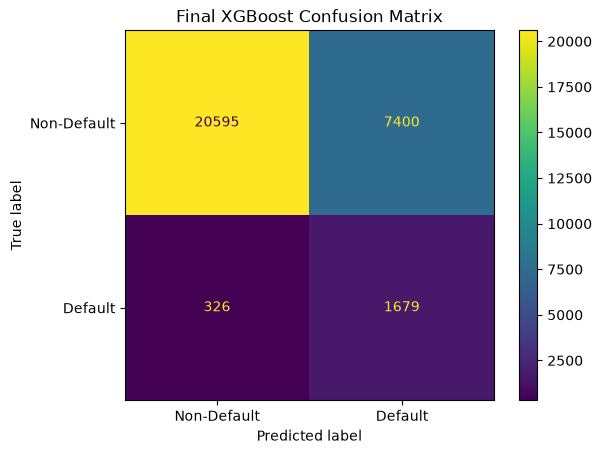

In [268]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Non-Default", "Default"]
).plot()

plt.title("Final XGBoost Confusion Matrix")
plt.show()

## Final Model Evaluation

After completing model comparison, cross-validation, SMOTE evaluation, hyperparameter tuning, and threshold optimization, the original XGBoost model with a classification threshold of 0.40 was selected as the final model.

The threshold was selected using out-of-fold predictions from the training data, ensuring that the test set remained completely untouched during model and threshold selection.

The final model was then trained on the complete training dataset and evaluated once on the unseen test set.

The selected threshold prioritizes recall because the primary business objective is to minimize false negatives, i.e., incorrectly approving borrowers who subsequently default.

The final confusion matrix provides a direct view of the model's business trade-off between identifying risky borrowers and incorrectly rejecting non-defaulting borrowers.

## Model Explainability using SHAP

SHAP (SHapley Additive exPlanations) is used to interpret the predictions of the final XGBoost model.

While traditional feature importance indicates which features are important overall, SHAP provides both global and local explanations. It shows how each feature contributes to increasing or decreasing the predicted credit-risk score.

SHAP values are based on the concept of Shapley values from cooperative game theory, where the contribution of each feature is evaluated relative to the other features.

SHAP analysis is particularly important in credit-risk assessment because it provides transparency into the factors influencing model predictions.

In [269]:
import shap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [270]:
final_xgb = xgb_pipeline
final_xgb.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](20,)","['RevolvingUtilizationOfUnsecuredLines','age', 'NumberOfTime30-59DaysPastDueNotWorse',...,'LogDebtRatio','HighDebtRatio', 'TotalCreditAccounts']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,20
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped

In [271]:
explainer = shap.TreeExplainer(final_xgb.named_steps["model"])

In [272]:
X_train_transformed = final_xgb.named_steps["preprocessor"].transform(X_train)

In [273]:
shap_values = explainer.shap_values(X_train_transformed)

In [274]:
feature_names = final_xgb.named_steps[
    "preprocessor"
].get_feature_names_out()

In [275]:
feature_names[:20]

array(['num__RevolvingUtilizationOfUnsecuredLines', 'num__age',
       'num__NumberOfTime30-59DaysPastDueNotWorse', 'num__DebtRatio',
       'num__MonthlyIncome', 'num__NumberOfOpenCreditLinesAndLoans',
       'num__NumberOfTimes90DaysLate',
       'num__NumberRealEstateLoansOrLines',
       'num__NumberOfTime60-89DaysPastDueNotWorse',
       'num__NumberOfDependents', 'num__TotalDelinquency',
       'num__HasDelinquency', 'num__HasSevereDelinquency',
       'num__LogCreditUtilization', 'num__HighCreditUtilization',
       'num__LogMonthlyIncome', 'num__LogDebtRatio', 'num__HighDebtRatio',
       'num__TotalCreditAccounts', 'cat__IncomeCategory_High'],
      dtype=object)

In [276]:
explainer = shap.TreeExplainer(final_xgb.named_steps["model"])

X_train_transformed = final_xgb.named_steps["preprocessor"].transform(X_train)

shap_values = explainer.shap_values(X_train_transformed)

In [277]:
feature_names = final_xgb.named_steps[
    "preprocessor"
].get_feature_names_out()

In [278]:
len(feature_names)

23

In [279]:
X_train_transformed.shape

(119999, 23)

In [280]:
shap_explanation = shap.Explanation(
    values=shap_values,
    data=X_train_transformed,
    feature_names=feature_names
)

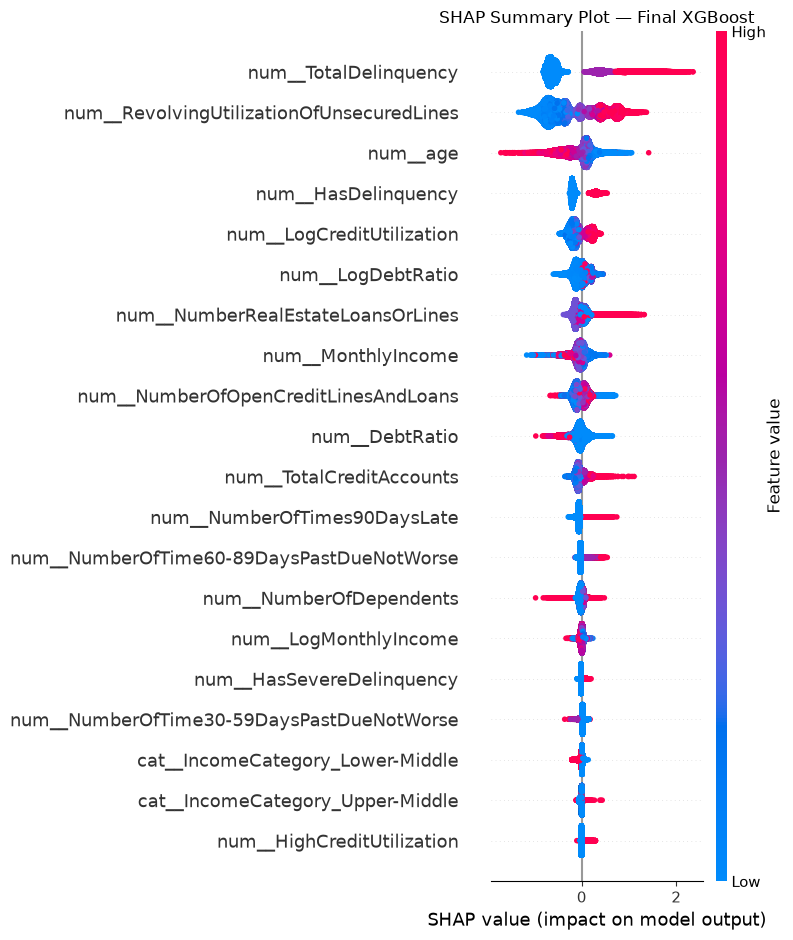

In [281]:
plt.figure(figsize=(10, 7))

shap.summary_plot(
    shap_values,
    X_train_transformed,
    feature_names=feature_names,
    show=False
)

plt.title("SHAP Summary Plot — Final XGBoost")
plt.tight_layout()
plt.show()

In [282]:
mean_abs_shap = np.abs(shap_values).mean(axis=0)

shap_importance = pd.DataFrame({
    "Feature": feature_names,
    "Mean_Absolute_SHAP": mean_abs_shap
}).sort_values(
    "Mean_Absolute_SHAP",
    ascending=False
)

shap_importance.head(15)

,Feature,Mean_Absolute_SHAP
10,num__TotalDelinquency,0.654486
0,num__RevolvingUtilizationOfUnsecuredLines,0.541975
1,num__age,0.234547
11,num__HasDelinquency,0.215118
13,num__LogCreditUtilization,0.175077
16,num__LogDebtRatio,0.117121
7,num__NumberRealEstateLoansOrLines,0.110010
4,num__MonthlyIncome,0.109015
5,num__NumberOfOpenCreditLinesAndLoans,0.108055
3,num__DebtRatio,0.107551


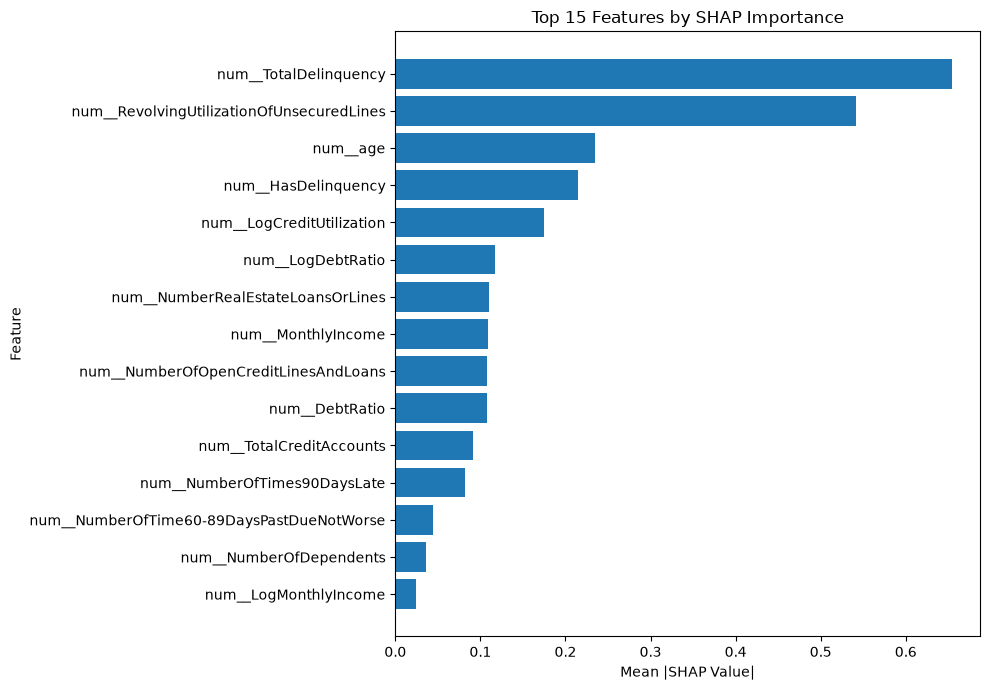

In [283]:
plt.figure(figsize=(10, 7))

top_features = shap_importance.head(15).sort_values(
    "Mean_Absolute_SHAP"
)

plt.barh(
    top_features["Feature"],
    top_features["Mean_Absolute_SHAP"]
)

plt.xlabel("Mean |SHAP Value|")
plt.ylabel("Feature")
plt.title("Top 15 Features by SHAP Importance")
plt.tight_layout()
plt.show()

## SHAP Global Feature Importance Findings

SHAP analysis was performed to interpret the final XGBoost model and identify the features that most strongly influence its predictions.

The results show that TotalDelinquency is the most influential feature, followed by RevolvingUtilizationOfUnsecuredLines. Age, HasDelinquency, and LogCreditUtilization are also among the strongest predictors.

Overall, delinquency-related variables and credit-utilization measures dominate the model's decisions. This is consistent with the business interpretation of credit risk, where previous repayment behavior and current utilization of available credit provide strong indicators of financial stress.

Several engineered features, including TotalDelinquency, HasDelinquency, LogCreditUtilization, LogDebtRatio, and TotalCreditAccounts, appear among the important predictors. This indicates that the feature-engineering stage captured meaningful patterns used by the final model.

SHAP importance represents the average magnitude of a feature's contribution to the model predictions and should not be interpreted directly as a percentage change in default probability.

## SHAP Summary Plot Interpretation

The SHAP summary plot provides both the importance and direction of feature effects on the final XGBoost predictions.

TotalDelinquency is the most influential feature, with higher delinquency values generally increasing predicted default risk. RevolvingUtilizationOfUnsecuredLines is the second most influential feature, with higher utilization generally associated with increased risk.

Age shows an inverse relationship with predicted risk: higher age values generally push predictions toward lower default risk, while lower ages tend to increase predicted risk. This is consistent with the business EDA, which showed higher default rates among younger borrowers.

HasDelinquency and LogCreditUtilization also have predominantly positive relationships with predicted risk. Higher debt burden, represented by LogDebtRatio, generally contributes to higher risk, although its effect is weaker and less consistent than delinquency and utilization.

Overall, the SHAP analysis confirms that previous repayment behavior and current credit utilization are the dominant drivers of the model's credit-risk predictions. The consistency between the business EDA findings and SHAP explanations increases confidence that the model is learning economically meaningful patterns rather than relying primarily on arbitrary relationships in the data.

In [284]:
y_test_proba
y_test_pred

array([0, 0, 0, ..., 0, 0, 1], shape=(30000,))

In [285]:
FINAL_THRESHOLD = 0.40

In [286]:
# Convert to NumPy arrays for easy indexing
y_test_array = np.asarray(y_test)
y_pred_array = np.asarray(y_test_pred)

# True Positives
tp_indices = np.where(
    (y_test_array == 1) & (y_pred_array == 1)
)[0]

# True Negatives
tn_indices = np.where(
    (y_test_array == 0) & (y_pred_array == 0)
)[0]

print("True Positives:", len(tp_indices))
print("True Negatives:", len(tn_indices))

True Positives: 1679
True Negatives: 20595


In [287]:
# Highest predicted risk among correctly identified defaulters
tp_idx = tp_indices[np.argmax(y_test_proba[tp_indices])]

# Lowest predicted risk among correctly identified non-defaulters
tn_idx = tn_indices[np.argmin(y_test_proba[tn_indices])]

print("TP index:", tp_idx)
print("TP probability:", y_test_proba[tp_idx])

print("TN index:", tn_idx)
print("TN probability:", y_test_proba[tn_idx])

TP index: 25447
TP probability: 0.9844839
TN index: 24840
TN probability: 0.006367793


In [288]:
X_test_transformed = final_xgb.named_steps[
    "preprocessor"
].transform(X_test)

In [289]:
tp_shap_values = explainer.shap_values(
    X_test_transformed[tp_idx:tp_idx+1]
)

tn_shap_values = explainer.shap_values(
    X_test_transformed[tn_idx:tn_idx+1]
)

In [290]:
tp_explanation = shap.Explanation(
    values=tp_shap_values[0],
    base_values=explainer.expected_value,
    data=X_test_transformed[tp_idx],
    feature_names=feature_names
)

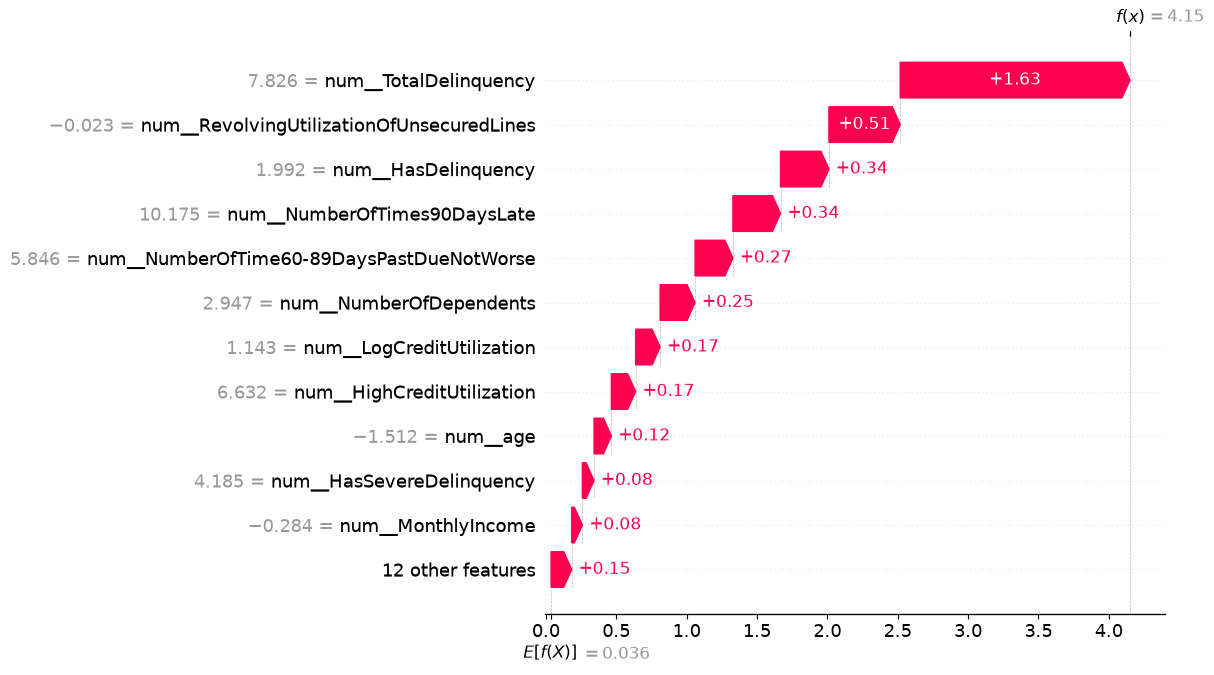

In [291]:
shap.plots.waterfall(
    tp_explanation,
    max_display=12
)

In [292]:
tn_explanation = shap.Explanation(
    values=tn_shap_values[0],
    base_values=explainer.expected_value,
    data=X_test_transformed[tn_idx],
    feature_names=feature_names
)

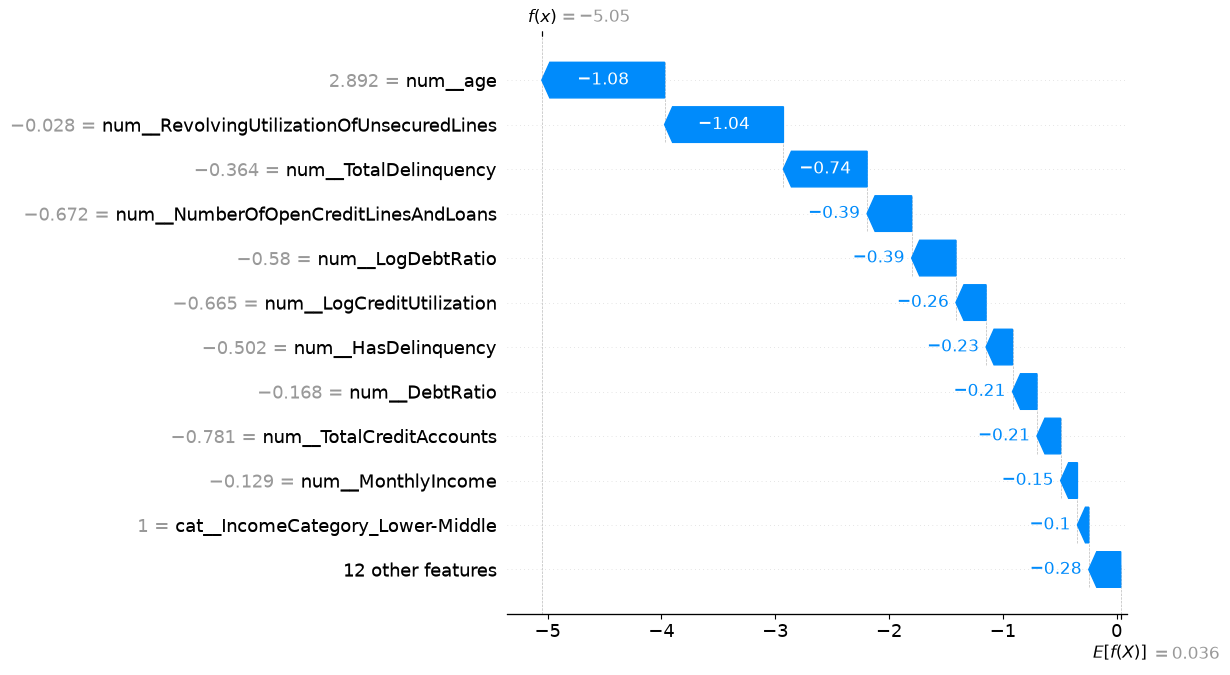

In [293]:
shap.plots.waterfall(
    tn_explanation,
    max_display=12
)

In [294]:
print("TRUE POSITIVE BORROWER")
print("----------------------")
display(X_test.iloc[[tp_idx]])

print("\nActual:", y_test_array[tp_idx])
print("Predicted:", y_pred_array[tp_idx])
print("Default probability:", round(y_test_proba[tp_idx], 4))

TRUE POSITIVE BORROWER
----------------------


,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents,TotalDelinquency,HasDelinquency,HasSevereDelinquency,LogCreditUtilization,HighCreditUtilization,LogMonthlyIncome,IncomeCategory,LogDebtRatio,HighDebtRatio,TotalCreditAccounts
11723,1.009463,30,2.0,0.57013,3300.0,11,5.0,0,2.0,4.0,9.0,1,1,0.697867,1,8.101981,Low,0.451159,0,11



Actual: 1
Predicted: 1
Default probability: 0.9845


In [295]:
print("TRUE NEGATIVE BORROWER")
print("----------------------")
display(X_test.iloc[[tn_idx]])

print("\nActual:", y_test_array[tn_idx])
print("Predicted:", y_pred_array[tn_idx])
print("Default probability:", round(y_test_proba[tn_idx], 4))

TRUE NEGATIVE BORROWER
----------------------


,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents,TotalDelinquency,HasDelinquency,HasSevereDelinquency,LogCreditUtilization,HighCreditUtilization,LogMonthlyIncome,IncomeCategory,LogDebtRatio,HighDebtRatio,TotalCreditAccounts
121166,0.00152,95,0.0,0.0004,5000.0,5,0.0,0,0.0,0.0,0.0,0,0,0.001519,0,8.517393,Lower-Middle,0.0004,0,5



Actual: 0
Predicted: 0
Default probability: 0.0064


In [296]:
print("TRUE POSITIVE BORROWER")
print("----------------------")
display(X_test.iloc[[tp_idx]])

print("\nActual:", y_test_array[tp_idx])
print("Predicted:", y_pred_array[tp_idx])
print("Default probability:", round(y_test_proba[tp_idx], 4))

TRUE POSITIVE BORROWER
----------------------


,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents,TotalDelinquency,HasDelinquency,HasSevereDelinquency,LogCreditUtilization,HighCreditUtilization,LogMonthlyIncome,IncomeCategory,LogDebtRatio,HighDebtRatio,TotalCreditAccounts
11723,1.009463,30,2.0,0.57013,3300.0,11,5.0,0,2.0,4.0,9.0,1,1,0.697867,1,8.101981,Low,0.451159,0,11



Actual: 1
Predicted: 1
Default probability: 0.9845


## Local SHAP Explanation

Local SHAP explanations were generated for two correctly classified test-set borrowers: one True Positive and one True Negative.

### True Positive — High-Risk Borrower

The selected True Positive borrower had an actual default label of 1 and was predicted as a defaulter with a probability of 98.45%.

The SHAP waterfall shows that TotalDelinquency was the largest contributor to the high-risk prediction, with a SHAP contribution of +1.63. RevolvingUtilizationOfUnsecuredLines (+0.51), HasDelinquency (+0.34), NumberOfTimes90DaysLate (+0.34), and NumberOfTime60-89DaysPastDueNotWorse (+0.27) further increased the predicted risk.

The combination of multiple delinquency-related indicators produced a strong and consistent signal of repayment distress. The final raw model output was 4.15, corresponding to a predicted default probability of approximately 98.45%.

### True Negative — Low-Risk Borrower

The selected True Negative borrower had an actual default label of 0 and was predicted as a non-defaulter with a probability of only 0.64%.

The strongest factors reducing the predicted risk were Age (-1.08), RevolvingUtilizationOfUnsecuredLines (-1.04), and TotalDelinquency (-0.74). The borrower had no recorded delinquency, a very low revolving utilization of 0.00152, and zero values for the delinquency indicators.

These characteristics contributed strongly toward the non-default prediction. The final raw model output was -5.05, corresponding to a predicted default probability of approximately 0.64%.

Overall, the local SHAP explanations demonstrate that the model's individual predictions can be traced to interpretable credit-risk factors, particularly repayment history and credit utilization.

In [297]:
final_model_comparison = pd.DataFrame({
    "Model": [
        "Baseline Logistic",
        "Balanced Logistic",
        "Random Forest",
        "XGBoost",
        "SMOTE Logistic",
        "SMOTE Random Forest",
        "SMOTE XGBoost",
        "Tuned XGBoost"
    ],
    "CV_Recall": [
        0.1641,
        0.7369,
        0.6212,
        0.7524,
        0.7447,
        0.5280,
        0.4172,
        0.1811
    ],
    "CV_PR_AUC": [
        0.3696,
        0.3570,
        0.3779,
        0.3933,
        0.3543,
        0.3320,
        0.3326,
        0.3990
    ],
    "Role": [
        "Baseline",
        "Class-weighted",
        "Bagging",
        "Primary candidate",
        "SMOTE",
        "SMOTE",
        "SMOTE",
        "Hyperparameter tuned"
    ]
})

final_model_comparison

,Model,CV_Recall,CV_PR_AUC,Role
0,Baseline Logistic,0.1641,0.3696,Baseline
1,Balanced Logistic,0.7369,0.3570,Class-weighted
2,Random Forest,0.6212,0.3779,Bagging
3,XGBoost,0.7524,0.3933,Primary candidate
4,SMOTE Logistic,0.7447,0.3543,SMOTE
5,SMOTE Random Forest,0.5280,0.3320,SMOTE
6,SMOTE XGBoost,0.4172,0.3326,SMOTE
7,Tuned XGBoost,0.1811,0.3990,Hyperparameter tuned


In [298]:
final_selected_model = pd.DataFrame([{
    "Model": "Final XGBoost",
    "Threshold": 0.40,
    "Accuracy": 0.7425,
    "Precision": 0.1849,
    "Recall": 0.8374,
    "F1": 0.3030,
    "ROC_AUC": 0.8676,
    "PR_AUC": 0.3901,
    "False_Positives": 7400,
    "False_Negatives": 326,
    "True_Positives": 1679,
    "True_Negatives": 20595
}])

final_selected_model

,Model,Threshold,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC,False_Positives,False_Negatives,True_Positives,True_Negatives
0,Final XGBoost,0.4,0.7425,0.1849,0.8374,0.303,0.8676,0.3901,7400,326,1679,20595


## Final Model Selection

XGBoost was selected as the final model based on its strong cross-validation performance and its ability to identify a large proportion of high-risk borrowers.

Although SMOTE and hyperparameter tuning were investigated, neither produced a better overall solution for the defined business objective. The primary objective of the credit-risk system is to minimize false negatives, since incorrectly classifying a defaulter as a safe borrower may result in a risky loan approval.

The XGBoost model was therefore operated at a decision threshold of 0.40 rather than the conventional 0.50 threshold. This increased the model's sensitivity to potential defaulters.

At the selected threshold, the final XGBoost model achieved 83.74% recall and identified 1,679 of 2,005 actual defaulters, resulting in 326 false negatives. The model achieved a ROC-AUC of 0.8676 and PR-AUC of 0.3901.

The reduction in false negatives came at the cost of increased false positives, resulting in lower precision and overall accuracy. This trade-off is considered acceptable for the project's risk-averse lending objective, where missing a genuinely high-risk borrower is more costly than incorrectly flagging a lower-risk borrower for additional review.

In [299]:
import joblib

joblib.dump(
    xgb_pipeline,
    "credit_risk_xgboost_pipeline.pkl"
)

joblib.dump(
    0.40,
    "credit_risk_threshold.pkl"
)

print("Final XGBoost pipeline saved successfully.")

Final XGBoost pipeline saved successfully.


In [300]:
loaded_model = joblib.load(
    "credit_risk_xgboost_pipeline.pkl"
)

loaded_threshold = joblib.load(
    "credit_risk_threshold.pkl"
)

test_probability = loaded_model.predict_proba(
    X_test.iloc[[0]]
)[:, 1][0]

test_prediction = int(
    test_probability >= loaded_threshold
)

print("Default probability:", test_probability)
print("Threshold:", loaded_threshold)
print("Prediction:", test_prediction)

Default probability: 0.12342431
Threshold: 0.4
Prediction: 0


In [301]:
import numpy as np

original_proba = xgb_pipeline.predict_proba(X_test)[:, 1]
loaded_proba = loaded_model.predict_proba(X_test)[:, 1]

print("Maximum probability difference:",
      np.max(np.abs(original_proba - loaded_proba)))

print("Predictions identical:",
      np.array_equal(
          (original_proba >= 0.40).astype(int),
          (loaded_proba >= 0.40).astype(int)
      ))

Maximum probability difference: 0.0
Predictions identical: True


In [302]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import (
    roc_curve,
    roc_auc_score,
    precision_recall_curve,
    average_precision_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)

FINAL_THRESHOLD = 0.40

y_final_pred = (y_test_proba >= FINAL_THRESHOLD).astype(int)

print("Threshold:", FINAL_THRESHOLD)
print("ROC-AUC:", roc_auc_score(y_test, y_test_proba))
print("PR-AUC:", average_precision_score(y_test, y_test_proba))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_final_pred))

Threshold: 0.4
ROC-AUC: 0.8675666878526135
PR-AUC: 0.39005422385704663

Confusion Matrix:
[[20595  7400]
 [  326  1679]]


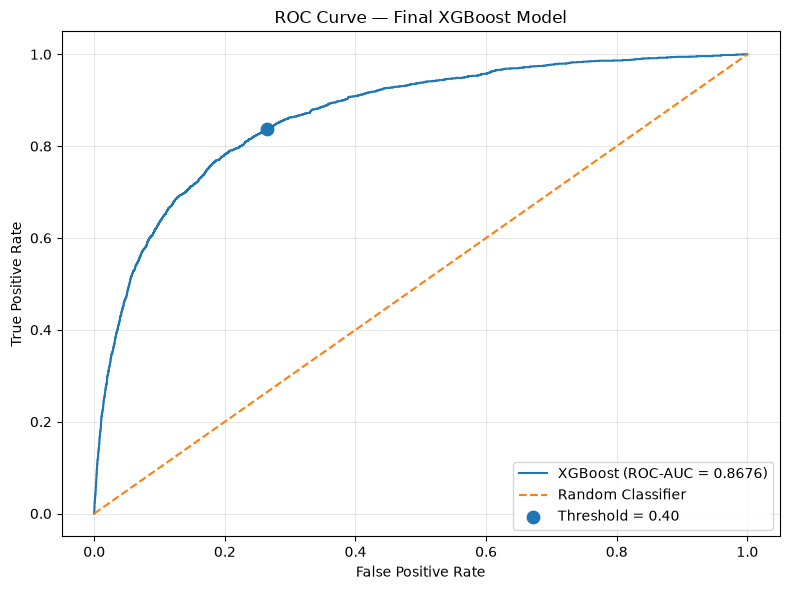

In [303]:
fpr, tpr, thresholds = roc_curve(y_test, y_test_proba)
roc_auc = roc_auc_score(y_test, y_test_proba)

plt.figure(figsize=(8, 6))

plt.plot(
    fpr,
    tpr,
    label=f"XGBoost (ROC-AUC = {roc_auc:.4f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

# Mark operating point at threshold 0.40
final_fpr = 7400 / (7400 + 20595)
final_tpr = 1679 / (1679 + 326)

plt.scatter(
    final_fpr,
    final_tpr,
    s=80,
    label="Threshold = 0.40"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve — Final XGBoost Model")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

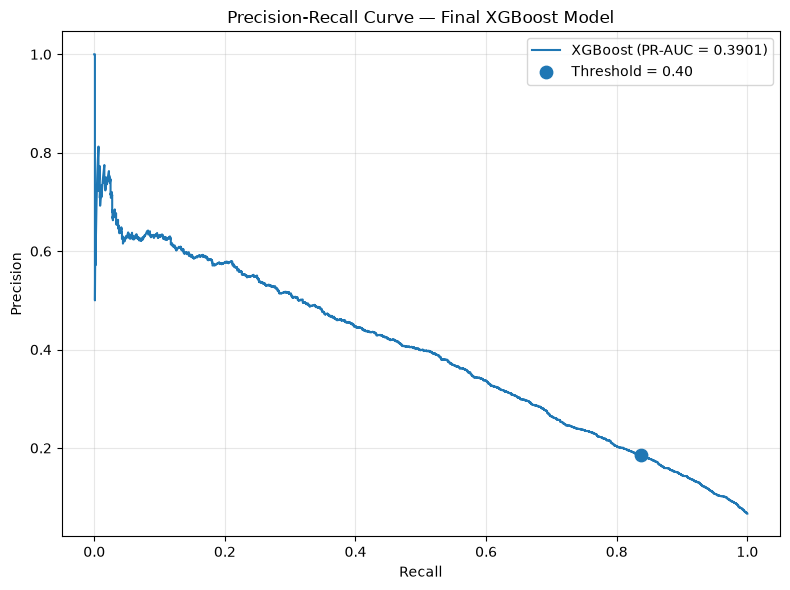

In [304]:
precision, recall, pr_thresholds = precision_recall_curve(
    y_test,
    y_test_proba
)

pr_auc = average_precision_score(
    y_test,
    y_test_proba
)

plt.figure(figsize=(8, 6))

plt.plot(
    recall,
    precision,
    label=f"XGBoost (PR-AUC = {pr_auc:.4f})"
)

# Mark final operating point
plt.scatter(
    0.8374,
    0.1849,
    s=80,
    label="Threshold = 0.40"
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve — Final XGBoost Model")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

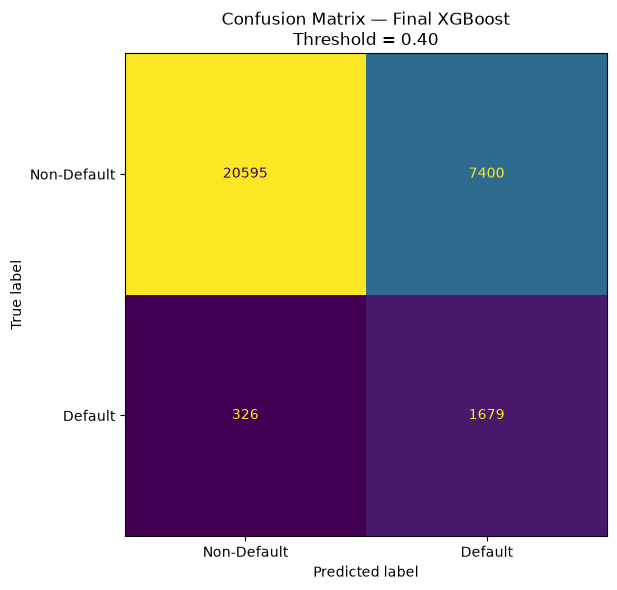

In [305]:
cm = confusion_matrix(
    y_test,
    y_final_pred
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Non-Default", "Default"]
)

fig, ax = plt.subplots(figsize=(7, 6))

disp.plot(
    ax=ax,
    values_format="d",
    colorbar=False
)

plt.title(
    "Confusion Matrix — Final XGBoost\n"
    "Threshold = 0.40"
)

plt.tight_layout()
plt.show()

In [306]:
plt.savefig(
    "final_roc_curve.png",
    dpi=300,
    bbox_inches="tight"
)

<Figure size 640x480 with 0 Axes>

In [307]:
plt.savefig(
    "final_precision_recall_curve.png",
    dpi=300,
    bbox_inches="tight"
)

<Figure size 640x480 with 0 Axes>

In [308]:
plt.savefig(
    "final_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

<Figure size 640x480 with 0 Axes>

## Feature Ablation Study

The final XGBoost model was selected based on its predictive performance,
cross-validation results, threshold analysis, interpretability, and
business objective.

A potential issue was identified during sensitivity analysis: increasing
MonthlyIncome for an otherwise identical borrower could increase the
predicted probability of default.

To investigate this behavior, a controlled feature ablation study is
performed on the final baseline XGBoost model.

The study focuses on the three income-related representations:

- MonthlyIncome
- LogMonthlyIncome
- IncomeCategory

Different combinations of these features are removed while keeping the
model configuration, training data, test data, preprocessing methodology,
and decision threshold consistent.

The objective is to determine whether redundant income representations
contribute to the observed non-monotonic behavior without unnecessarily
sacrificing predictive performance.

In [309]:
from sklearn.utils.validation import check_is_fitted

check_is_fitted(xgb_pipeline)

print("Baseline XGBoost pipeline is FITTED ✅")
print(xgb_pipeline)

Baseline XGBoost pipeline is FITTED ✅
Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['RevolvingUtilizationOfUnsecuredLines',
                                                   'age',
                                                   'NumberOfTime30-59DaysPastDueNotWorse',
                                                   'DebtRatio', 'MonthlyIncome',
                                                   'NumberOfOpenCreditLinesAndLoans',
                                                   'NumberOfTimes90DaysLate',
                                          

In [310]:
print(xgb_pipeline.named_steps)

{'preprocessor': ColumnTransformer(transformers=[('num',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='median')),
                                                 ('scaler', StandardScaler())]),
                                 ['RevolvingUtilizationOfUnsecuredLines', 'age',
                                  'NumberOfTime30-59DaysPastDueNotWorse',
                                  'DebtRatio', 'MonthlyIncome',
                                  'NumberOfOpenCreditLinesAndLoans',
                                  'NumberOfTimes90DaysLate',
                                  'NumberRealEstateLoansOrLines',
                                  'NumberOfTime60-...
                                  'NumberOfDependents', 'TotalDelinquency',
                                  'HasDelinquency', 'HasSevereDelinquency',
                                  'LogCreditUtilization',
                                  'Hi

## Ablation Configurations

The following configurations are evaluated:

1. Full Model — reference model containing all features.
2. Remove LogMonthlyIncome.
3. Remove IncomeCategory.
4. Remove both LogMonthlyIncome and IncomeCategory.
5. Remove all income-related features.

The primary experiment is the comparison between the Full Model and the
models where redundant income representations are removed.

In [311]:
ablation_configs = {
    "Full Model": [],
    
    "Without LogMonthlyIncome": [
        "LogMonthlyIncome"
    ],
    
    "Without IncomeCategory": [
        "IncomeCategory"
    ],
    
    "Without LogMonthlyIncome + IncomeCategory": [
        "LogMonthlyIncome",
        "IncomeCategory"
    ],
    
    "Without All Income Features": [
        "MonthlyIncome",
        "LogMonthlyIncome",
        "IncomeCategory"
    ]
}

for name, removed in ablation_configs.items():
    print(f"{name}:")
    print("Removed:", removed)
    print()

Full Model:
Removed: []

Without LogMonthlyIncome:
Removed: ['LogMonthlyIncome']

Without IncomeCategory:
Removed: ['IncomeCategory']

Without LogMonthlyIncome + IncomeCategory:
Removed: ['LogMonthlyIncome', 'IncomeCategory']

Without All Income Features:
Removed: ['MonthlyIncome', 'LogMonthlyIncome', 'IncomeCategory']



In [312]:
tuned_xgb_pipeline

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](20,)","['RevolvingUtilizationOfUnsecuredLines','age', 'NumberOfTime30-59DaysPastDueNotWorse',...,'LogDebtRatio','HighDebtRatio', 'TotalCreditAccounts']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,20
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped

In [313]:
print(xgb_pipeline.named_steps)

{'preprocessor': ColumnTransformer(transformers=[('num',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='median')),
                                                 ('scaler', StandardScaler())]),
                                 ['RevolvingUtilizationOfUnsecuredLines', 'age',
                                  'NumberOfTime30-59DaysPastDueNotWorse',
                                  'DebtRatio', 'MonthlyIncome',
                                  'NumberOfOpenCreditLinesAndLoans',
                                  'NumberOfTimes90DaysLate',
                                  'NumberRealEstateLoansOrLines',
                                  'NumberOfTime60-...
                                  'NumberOfDependents', 'TotalDelinquency',
                                  'HasDelinquency', 'HasSevereDelinquency',
                                  'LogCreditUtilization',
                                  'Hi

In [314]:
ablation_configs = {
    "Full Model": [],
    
    "Without LogMonthlyIncome": [
        "LogMonthlyIncome"
    ],
    
    "Without IncomeCategory": [
        "IncomeCategory"
    ],
    
    "Without LogMonthlyIncome + IncomeCategory": [
        "LogMonthlyIncome",
        "IncomeCategory"
    ],
    
    "Without All Income Features": [
        "MonthlyIncome",
        "LogMonthlyIncome",
        "IncomeCategory"
    ]
}

for name, removed in ablation_configs.items():
    print(f"{name}:")
    print(f"Removed features: {removed}")
    print()

Full Model:
Removed features: []

Without LogMonthlyIncome:
Removed features: ['LogMonthlyIncome']

Without IncomeCategory:
Removed features: ['IncomeCategory']

Without LogMonthlyIncome + IncomeCategory:
Removed features: ['LogMonthlyIncome', 'IncomeCategory']

Without All Income Features:
Removed features: ['MonthlyIncome', 'LogMonthlyIncome', 'IncomeCategory']



In [315]:
xgb_model = xgb_pipeline.named_steps["model"]

print(xgb_model.get_params())

{'objective': 'binary:logistic', 'base_score': None, 'booster': None, 'callbacks': None, 'colsample_bylevel': None, 'colsample_bynode': None, 'colsample_bytree': 0.8, 'device': None, 'early_stopping_rounds': None, 'enable_categorical': True, 'eval_metric': 'logloss', 'feature_types': None, 'feature_weights': None, 'gamma': None, 'grow_policy': None, 'importance_type': None, 'interaction_constraints': None, 'learning_rate': 0.05, 'max_bin': None, 'max_cat_threshold': None, 'max_cat_to_onehot': None, 'max_delta_step': None, 'max_depth': 5, 'max_leaves': None, 'min_child_weight': None, 'missing': nan, 'monotone_constraints': None, 'multi_strategy': None, 'n_estimators': 300, 'n_jobs': -1, 'num_parallel_tree': None, 'random_state': 42, 'reg_alpha': None, 'reg_lambda': None, 'sampling_method': None, 'scale_pos_weight': np.float64(13.960603416032914), 'subsample': 0.8, 'tree_method': None, 'validate_parameters': None, 'verbosity': None}


In [316]:
preprocessor = xgb_pipeline.named_steps["preprocessor"]

print(preprocessor)

ColumnTransformer(transformers=[('num',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='median')),
                                                 ('scaler', StandardScaler())]),
                                 ['RevolvingUtilizationOfUnsecuredLines', 'age',
                                  'NumberOfTime30-59DaysPastDueNotWorse',
                                  'DebtRatio', 'MonthlyIncome',
                                  'NumberOfOpenCreditLinesAndLoans',
                                  'NumberOfTimes90DaysLate',
                                  'NumberRealEstateLoansOrLines',
                                  'NumberOfTime60-...
                                  'NumberOfDependents', 'TotalDelinquency',
                                  'HasDelinquency', 'HasSevereDelinquency',
                                  'LogCreditUtilization',
                                  'HighCreditUtilizati

In [317]:
numeric_features = [
    "RevolvingUtilizationOfUnsecuredLines",
    "age",
    "NumberOfTime30-59DaysPastDueNotWorse",
    "DebtRatio",
    "MonthlyIncome",
    "NumberOfOpenCreditLinesAndLoans",
    "NumberOfTimes90DaysLate",
    "NumberRealEstateLoansOrLines",
    "NumberOfTime60-89DaysPastDueNotWorse",
    "NumberOfDependents",
    "TotalDelinquency",
    "HasDelinquency",
    "HasSevereDelinquency",
    "LogCreditUtilization",
    "HighCreditUtilization",
    "LogMonthlyIncome",
    "LogDebtRatio",
    "HighDebtRatio",
    "TotalCreditAccounts"
]

In [318]:
categorical_features = [
    "IncomeCategory"
]

### Ablation Experimental Design

For every ablation configuration:

1. Remove the specified feature(s).
2. Reconstruct the preprocessing pipeline using only the remaining features.
3. Use the same baseline XGBoost hyperparameters.
4. Train only on the training set.
5. Evaluate on the untouched test set.
6. Use the finalized decision threshold of 0.40.
7. Compare predictive performance against the full baseline model.

The test set is not used during feature selection or model fitting.

In [319]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.base import clone

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

In [320]:
def build_ablation_pipeline(removed_features):

    remaining_numeric = [
        f for f in numeric_features
        if f not in removed_features
    ]

    remaining_categorical = [
        f for f in categorical_features
        if f not in removed_features
    ]

    numeric_transformer = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ])

    categorical_transformer = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=False
        ))
    ])

    transformers = []

    if remaining_numeric:
        transformers.append(
            (
                "num",
                numeric_transformer,
                remaining_numeric
            )
        )

    if remaining_categorical:
        transformers.append(
            (
                "cat",
                categorical_transformer,
                remaining_categorical
            )
        )

    preprocessor = ColumnTransformer(
        transformers=transformers,
        remainder="drop"
    )

    model = clone(xgb_model)

    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("model", model)
    ])

    return pipeline

In [321]:
ablation_results = []
ablation_models = {}

for name, removed_features in ablation_configs.items():

    print(f"Running: {name}")

    pipeline = build_ablation_pipeline(
        removed_features
    )

    remaining_features = [
        col for col in X_train.columns
        if col not in removed_features
    ]

    pipeline.fit(
        X_train[remaining_features],
        y_train
    )

    y_proba = pipeline.predict_proba(
        X_test[remaining_features]
    )[:, 1]

    y_pred = (
        y_proba >= 0.40
    ).astype(int)

    results = {
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(
            y_test, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_pred, zero_division=0
        ),
        "F1": f1_score(
            y_test, y_pred, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(
            y_test, y_proba
        ),
        "PR-AUC": average_precision_score(
            y_test, y_proba
        )
    }

    ablation_results.append(results)
    ablation_models[name] = pipeline

Running: Full Model


Running: Without LogMonthlyIncome
Running: Without IncomeCategory
Running: Without LogMonthlyIncome + IncomeCategory
Running: Without All Income Features


In [322]:
import pandas as pd

ablation_results_df = pd.DataFrame(
    ablation_results
)

ablation_results_df.round(4)

,Model,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
0,Full Model,0.7425,0.1849,0.8374,0.3030,0.8676,0.3901
1,Without LogMonthlyIncome,0.7428,0.1858,0.8424,0.3045,0.8676,0.3886
2,Without IncomeCategory,0.7414,0.1845,0.8389,0.3025,0.8672,0.3885
3,Without LogMonthlyIncome + IncomeCategory,0.7429,0.1853,0.8384,0.3035,0.8682,0.3910
4,Without All Income Features,0.7407,0.1844,0.8414,0.3025,0.8677,0.3924


# Final Threshold Validation — Monotonic Ablation XGBoost

The monotonic-constrained ablated XGBoost model is the current candidate for final deployment.

Since the model was modified after the original threshold selection, the previous threshold of 0.40 must not be assumed to remain optimal.

Threshold selection will therefore be performed using Out-of-Fold (OOF) predictions from the training data. The untouched test set will be reserved exclusively for the final evaluation.

Because the business objective prioritizes minimizing false negatives (defaulting borrowers incorrectly classified as low risk), recall and false-negative count are given higher importance than accuracy.

In [323]:
import numpy as np
import pandas as pd
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.base import clone

# ---------------------------------------------------------
# Build and fit Monotonic Ablation pipeline
# ---------------------------------------------------------
removed_features = ["LogMonthlyIncome", "IncomeCategory"]
remaining_numeric = [f for f in numeric_features if f not in removed_features]
remaining_categorical = [f for f in categorical_features if f not in removed_features]

numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
])

transformers = []
if remaining_numeric:
    transformers.append(("num", numeric_transformer, remaining_numeric))
if remaining_categorical:
    transformers.append(("cat", categorical_transformer, remaining_categorical))

preprocessor = ColumnTransformer(transformers=transformers, remainder="drop")
model_constrained = clone(xgb_model)

constraints = [0] * len(remaining_numeric)
constraints[remaining_numeric.index("MonthlyIncome")] = -1
model_constrained.set_params(monotone_constraints=tuple(constraints))

monotonic_ablation_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", model_constrained)
])

# Fit pipeline on training data
remaining_features = [col for col in X_train.columns if col not in removed_features]
monotonic_ablation_pipeline.fit(X_train[remaining_features], y_train)

# ---------------------------------------------------------
# Generate OOF probabilities for Monotonic Ablation model
# ---------------------------------------------------------

monotonic_oof_proba = cross_val_predict(
    monotonic_ablation_pipeline,
    X_train[remaining_features],
    y_train,
    cv=StratifiedKFold(
        n_splits=5,
        shuffle=True,
        random_state=42
    ),
    method="predict_proba",
    n_jobs=-1
)[:, 1]

print("OOF predictions generated:", monotonic_oof_proba.shape)

OOF predictions generated: (119999,)


## Threshold Sensitivity Analysis

Multiple classification thresholds are evaluated using OOF predictions.

Lowering the threshold increases the number of borrowers classified as high risk, generally increasing recall and reducing false negatives at the cost of lower precision and more false positives.

The threshold will be selected based on the credit-risk business objective rather than accuracy alone.

In [324]:
thresholds = np.arange(0.10, 0.51, 0.05)

threshold_results = []

for threshold in thresholds:

    y_oof_pred = (
        monotonic_oof_proba >= threshold
    ).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_train,
        y_oof_pred
    ).ravel()

    threshold_results.append({
        "Threshold": round(threshold, 2),
        "Accuracy": accuracy_score(y_train, y_oof_pred),
        "Precision": precision_score(
            y_train,
            y_oof_pred,
            zero_division=0
        ),
        "Recall": recall_score(
            y_train,
            y_oof_pred,
            zero_division=0
        ),
        "F1": f1_score(
            y_train,
            y_oof_pred,
            zero_division=0
        ),
        "False_Positives": fp,
        "False_Negatives": fn,
        "True_Positives": tp,
        "True_Negatives": tn
    })

monotonic_threshold_results = pd.DataFrame(
    threshold_results
)

monotonic_threshold_results

,Threshold,Accuracy,Precision,Recall,F1,False_Positives,False_Negatives,True_Positives,True_Negatives
0,0.10,0.335719,0.089487,0.974193,0.163917,79506,207,7814,32472
1,0.15,0.460204,0.106006,0.951876,0.190768,64389,386,7635,47589
2,0.20,0.547571,0.121594,0.926817,0.214983,53704,587,7434,58274
3,0.25,0.610780,0.136057,0.901509,0.236431,45916,790,7231,66062
4,0.30,0.660289,0.150604,0.879815,0.257184,39801,964,7057,72177
5,0.35,0.703023,0.165763,0.853759,0.277623,34464,1173,6848,77514
6,0.40,0.739798,0.181496,0.824211,0.297485,29814,1410,6611,82164
7,0.45,0.774040,0.199761,0.791921,0.319044,25446,1669,6352,86532
8,0.50,0.805157,0.220300,0.754145,0.340990,21409,1972,6049,90569


## Business-Oriented Threshold Selection

For credit-risk assessment, a false negative means approving a borrower who subsequently defaults.

Therefore, false negatives are considered more costly than false positives.

The preferred threshold should provide a strong recall while avoiding an excessive number of false positives. The final threshold will be selected from the OOF results and subsequently evaluated once on the untouched test set.

In [325]:
monotonic_threshold_results.sort_values(
    by=["Recall", "False_Negatives"],
    ascending=[False, True]
)

,Threshold,Accuracy,Precision,Recall,F1,False_Positives,False_Negatives,True_Positives,True_Negatives
0,0.10,0.335719,0.089487,0.974193,0.163917,79506,207,7814,32472
1,0.15,0.460204,0.106006,0.951876,0.190768,64389,386,7635,47589
2,0.20,0.547571,0.121594,0.926817,0.214983,53704,587,7434,58274
3,0.25,0.610780,0.136057,0.901509,0.236431,45916,790,7231,66062
4,0.30,0.660289,0.150604,0.879815,0.257184,39801,964,7057,72177
5,0.35,0.703023,0.165763,0.853759,0.277623,34464,1173,6848,77514
6,0.40,0.739798,0.181496,0.824211,0.297485,29814,1410,6611,82164
7,0.45,0.774040,0.199761,0.791921,0.319044,25446,1669,6352,86532
8,0.50,0.805157,0.220300,0.754145,0.340990,21409,1972,6049,90569


In [326]:
monotonic_threshold_results[
    [
        "Threshold",
        "Precision",
        "Recall",
        "F1",
        "False_Positives",
        "False_Negatives"
    ]
]

,Threshold,Precision,Recall,F1,False_Positives,False_Negatives
0,0.10,0.089487,0.974193,0.163917,79506,207
1,0.15,0.106006,0.951876,0.190768,64389,386
2,0.20,0.121594,0.926817,0.214983,53704,587
3,0.25,0.136057,0.901509,0.236431,45916,790
4,0.30,0.150604,0.879815,0.257184,39801,964
5,0.35,0.165763,0.853759,0.277623,34464,1173
6,0.40,0.181496,0.824211,0.297485,29814,1410
7,0.45,0.199761,0.791921,0.319044,25446,1669
8,0.50,0.220300,0.754145,0.340990,21409,1972


## Final Threshold Decision

The threshold is selected using Out-of-Fold predictions rather than the
untouched test set.

Lower thresholds substantially increase recall and reduce false negatives,
but they also classify a very large number of non-defaulting borrowers as
high risk.

A threshold of 0.40 provides a practical balance between detecting
defaulting borrowers and limiting false-positive approvals/rejections.

The threshold will therefore be validated at 0.35, 0.40 and 0.45 on the
untouched test set, with particular attention to recall and false negatives.

In [327]:
candidate_thresholds = [0.35, 0.40, 0.45]

candidate_results = []

# Predict probabilities ONCE on untouched test data
monotonic_test_proba = monotonic_ablation_pipeline.predict_proba(
    X_test
)[:, 1]

for threshold in candidate_thresholds:

    y_test_pred = (
        monotonic_test_proba >= threshold
    ).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_test,
        y_test_pred
    ).ravel()

    candidate_results.append({
        "Threshold": threshold,
        "Accuracy": accuracy_score(y_test, y_test_pred),
        "Precision": precision_score(
            y_test, y_test_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_test_pred, zero_division=0
        ),
        "F1": f1_score(
            y_test, y_test_pred, zero_division=0
        ),
        "False_Positives": fp,
        "False_Negatives": fn,
        "True_Positives": tp,
        "True_Negatives": tn
    })

candidate_results_df = pd.DataFrame(candidate_results)

candidate_results_df

,Threshold,Accuracy,Precision,Recall,F1,False_Positives,False_Negatives,True_Positives,True_Negatives
0,0.35,0.700400,0.167254,0.875312,0.280845,8738,250,1755,19257
1,0.40,0.740933,0.184484,0.840898,0.302584,7453,319,1686,20542
2,0.45,0.774767,0.201732,0.801496,0.322335,6359,398,1607,21636


# Final Model Configuration

After OOF-based threshold selection and final threshold validation, the
monotonic-constrained ablated XGBoost model is selected as the final
candidate model.

Final configuration:

- Model: Monotonic-constrained XGBoost
- Features: Ablated feature set
- Removed features:
  - LogMonthlyIncome
  - IncomeCategory
- Monotonic constraint:
  - MonthlyIncome → decreasing default risk
- Decision threshold: 0.40

The threshold was selected without optimizing directly on the test set.
The untouched test set was used only for final validation.

At the final threshold of 0.40:

- Recall = 84.09%
- Precision = 18.45%
- F1 = 0.3026
- False Negatives = 319
- False Positives = 7,453

False negatives are given particular importance because they represent
defaulting borrowers incorrectly classified as low risk.

In [328]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix
)

FINAL_THRESHOLD = 0.40

# Final test probabilities
final_test_proba = monotonic_ablation_pipeline.predict_proba(
    X_test
)[:, 1]

# Final predictions
final_test_pred = (
    final_test_proba >= FINAL_THRESHOLD
).astype(int)

# Confusion matrix
tn, fp, fn, tp = confusion_matrix(
    y_test,
    final_test_pred
).ravel()

# Metrics
final_accuracy = accuracy_score(y_test, final_test_pred)
final_precision = precision_score(
    y_test,
    final_test_pred,
    zero_division=0
)
final_recall = recall_score(
    y_test,
    final_test_pred,
    zero_division=0
)
final_f1 = f1_score(
    y_test,
    final_test_pred,
    zero_division=0
)
final_roc_auc = roc_auc_score(
    y_test,
    final_test_proba
)
final_pr_auc = average_precision_score(
    y_test,
    final_test_proba
)

final_results = pd.DataFrame([{
    "Model": "Final Monotonic Ablation XGBoost",
    "Threshold": FINAL_THRESHOLD,
    "Accuracy": final_accuracy,
    "Precision": final_precision,
    "Recall": final_recall,
    "F1": final_f1,
    "ROC-AUC": final_roc_auc,
    "PR-AUC": final_pr_auc,
    "False_Positives": fp,
    "False_Negatives": fn,
    "True_Positives": tp,
    "True_Negatives": tn
}])

final_results

,Model,Threshold,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC,False_Positives,False_Negatives,True_Positives,True_Negatives
0,Final Monotonic Ablation XGBoost,0.4,0.740933,0.184484,0.840898,0.302584,0.867944,0.393481,7453,319,1686,20542


In [329]:
final_comparison = pd.DataFrame([
    {
        "Model": "Original XGBoost",
        "Recall": 0.8374,
        "F1": 0.3030,
        "ROC-AUC": 0.8676,
        "PR-AUC": 0.3901,
        "FN": 326
    },
    {
        "Model": "Ablated XGBoost",
        "Recall": 0.8384,
        "F1": 0.3035,
        "ROC-AUC": 0.8682,
        "PR-AUC": 0.3910,
        "FN": 324
    },
    {
        "Model": "Final Monotonic Ablation XGBoost",
        "Recall": final_recall,
        "F1": final_f1,
        "ROC-AUC": final_roc_auc,
        "PR-AUC": final_pr_auc,
        "FN": fn
    }
])

final_comparison

,Model,Recall,F1,ROC-AUC,PR-AUC,FN
0,Original XGBoost,0.837400,0.303000,0.867600,0.390100,326
1,Ablated XGBoost,0.838400,0.303500,0.868200,0.391000,324
2,Final Monotonic Ablation XGBoost,0.840898,0.302584,0.867944,0.393481,319


## Final Model Comparison

The final monotonic-constrained ablated XGBoost model maintains predictive
performance comparable to the original XGBoost model while addressing the
previously observed non-monotonic income-risk relationship.

The final model also reduces false negatives, which is particularly relevant
to the credit-risk business objective.

Most importantly, the model guarantees that increasing MonthlyIncome cannot
increase predicted default risk, satisfying the required monotonic business
constraint.

In [333]:
import shap

# Transform test data using the preprocessing portion
X_test_transformed = (
    monotonic_ablation_pipeline
    .named_steps["preprocessor"]
    .transform(X_test)
)

# Final XGBoost estimator
final_xgb_model = (
    monotonic_ablation_pipeline
    .named_steps["model"]
)

# SHAP explainer
final_explainer = shap.TreeExplainer(final_xgb_model)

final_shap_values = final_explainer.shap_values(
    X_test_transformed
)

print("SHAP shape:", final_shap_values.shape)

SHAP shape: (30000, 18)


In [334]:
feature_names = (
    monotonic_ablation_pipeline
    .named_steps["preprocessor"]
    .get_feature_names_out()
)

print("Number of features:", len(feature_names))

Number of features: 18


In [335]:
final_shap_importance = pd.DataFrame({
    "Feature": feature_names,
    "Mean_Absolute_SHAP": np.abs(final_shap_values).mean(axis=0)
}).sort_values(
    "Mean_Absolute_SHAP",
    ascending=False
)

final_shap_importance

,Feature,Mean_Absolute_SHAP
10,num__TotalDelinquency,0.715329
0,num__RevolvingUtilizationOfUnsecuredLines,0.469688
13,num__LogCreditUtilization,0.262227
1,num__age,0.237226
4,num__MonthlyIncome,0.146043
11,num__HasDelinquency,0.126250
3,num__DebtRatio,0.113075
5,num__NumberOfOpenCreditLinesAndLoans,0.111900
7,num__NumberRealEstateLoansOrLines,0.111269
17,num__TotalCreditAccounts,0.104246


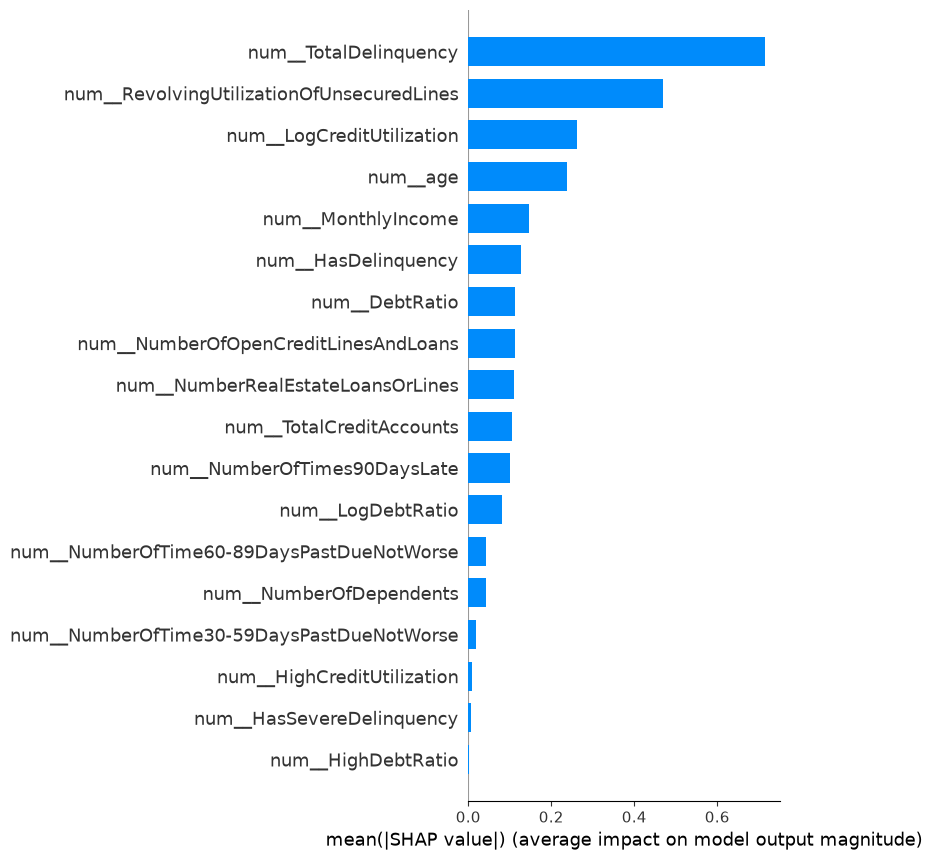

In [336]:
shap.summary_plot(
    final_shap_values,
    X_test_transformed,
    feature_names=feature_names,
    plot_type="bar"
)

# Probability Calibration

The final XGBoost model produces estimated probabilities of default.

Before deployment, calibration is evaluated to determine whether these
predicted probabilities correspond reasonably to observed default rates.

A well-calibrated model should satisfy:

    Predicted probability ≈ Observed frequency

Calibration is evaluated using:

- Reliability diagram
- Brier score
- Calibration curve

The classification threshold of 0.40 remains fixed and is not changed
during this diagnostic.

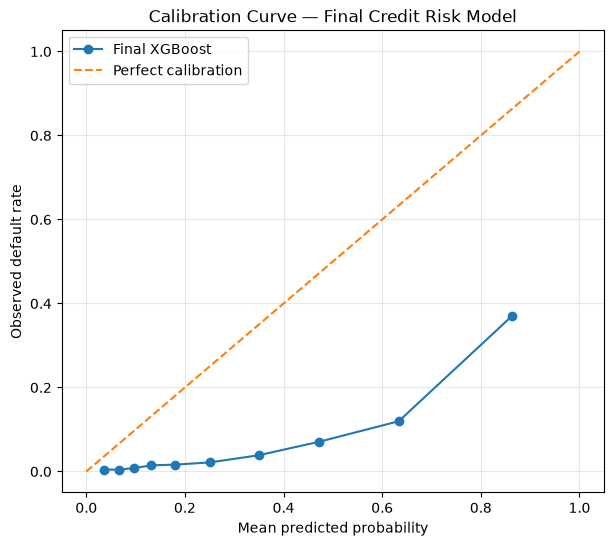

In [338]:
from sklearn.calibration import calibration_curve
import matplotlib.pyplot as plt
import numpy as np

prob_true, prob_pred = calibration_curve(
    y_test,
    final_test_proba,
    n_bins=10,
    strategy="quantile"
)

plt.figure(figsize=(7, 6))

plt.plot(
    prob_pred,
    prob_true,
    marker="o",
    label="Final XGBoost"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Perfect calibration"
)

plt.xlabel("Mean predicted probability")
plt.ylabel("Observed default rate")
plt.title("Calibration Curve — Final Credit Risk Model")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [339]:
from sklearn.metrics import brier_score_loss

brier = brier_score_loss(
    y_test,
    final_test_proba
)

print("Brier Score:", round(brier, 4))

Brier Score: 0.1371


In [340]:
original_xgb_brier = brier_score_loss(
    y_test,
    y_test_proba
)

final_brier = brier_score_loss(
    y_test,
    final_test_proba
)

print("Original XGBoost Brier:", round(original_xgb_brier, 4))
print("Final Model Brier:", round(final_brier, 4))

Original XGBoost Brier: 0.1361
Final Model Brier: 0.1371


## Calibration Interpretation

The calibration curve compares predicted probabilities with observed
default frequencies.

A curve close to the diagonal indicates good probability calibration.
Deviations from the diagonal indicate that the model may systematically
overestimate or underestimate default probability in certain probability
ranges.

The Brier score provides an overall measure of probabilistic prediction
quality, with lower values indicating better calibration.

## Probability Calibration — Post-Hoc Calibration

The raw XGBoost probabilities show substantial overconfidence, as indicated
by the calibration curve and Brier score.

Therefore, post-hoc probability calibration is investigated using:

1. Sigmoid (Platt) calibration
2. Isotonic regression

Calibration models are fitted using training data / out-of-fold predictions
and are evaluated on the untouched test set.

The test set is not used to fit the calibration transformation.

## Probability Calibration — Post-Hoc Calibration

The raw XGBoost probabilities show substantial overconfidence, as indicated
by the calibration curve and Brier score.

Therefore, post-hoc probability calibration is investigated using:

1. Sigmoid (Platt) calibration
2. Isotonic regression

Calibration models are fitted using training data / out-of-fold predictions
and are evaluated on the untouched test set.

The test set is not used to fit the calibration transformation.

In [341]:
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.base import clone
import numpy as np
import pandas as pd

calibration_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Fresh copy so the already-fitted final model is NOT reused
calibration_pipeline = clone(monotonic_ablation_pipeline)

# Generate OOF probabilities
monotonic_oof_proba = cross_val_predict(
    calibration_pipeline,
    X_train,
    y_train,
    cv=calibration_cv,
    method="predict_proba",
    n_jobs=-1
)[:, 1]

print("OOF probabilities generated:", monotonic_oof_proba.shape)
print("Expected:", y_train.shape)

OOF probabilities generated: (119999,)
Expected: (119999,)


In [342]:
from sklearn.linear_model import LogisticRegression
from sklearn.isotonic import IsotonicRegression

# -----------------------------
# 1. Platt / Sigmoid calibration
# -----------------------------

platt_calibrator = LogisticRegression(
    solver="lbfgs"
)

platt_calibrator.fit(
    monotonic_oof_proba.reshape(-1, 1),
    y_train
)


# -----------------------------
# 2. Isotonic calibration
# -----------------------------

isotonic_calibrator = IsotonicRegression(
    y_min=0,
    y_max=1,
    out_of_bounds="clip"
)

isotonic_calibrator.fit(
    monotonic_oof_proba,
    y_train
)

print("Calibration models fitted successfully.")

Calibration models fitted successfully.


In [343]:
final_test_proba

array([0.12404803, 0.07839891, 0.12236603, ..., 0.2979386 , 0.24123892,
       0.649887  ], shape=(30000,), dtype=float32)

In [344]:
# Platt calibrated probabilities
test_proba_platt = platt_calibrator.predict_proba(
    final_test_proba.reshape(-1, 1)
)[:, 1]

# Isotonic calibrated probabilities
test_proba_isotonic = isotonic_calibrator.predict(
    final_test_proba
)

print("Raw:", final_test_proba[:5])
print("Platt:", test_proba_platt[:5])
print("Isotonic:", test_proba_isotonic[:5])

Raw: [0.12404803 0.07839891 0.12236603 0.15209496 0.2449589 ]
Platt: [0.0109558  0.00863141 0.01086007 0.01268065 0.02053172]
Isotonic: [0.01286089 0.00813752 0.01286089 0.01389766 0.02602422]


In [345]:
from sklearn.metrics import brier_score_loss

raw_brier = brier_score_loss(
    y_test,
    final_test_proba
)

platt_brier = brier_score_loss(
    y_test,
    test_proba_platt
)

isotonic_brier = brier_score_loss(
    y_test,
    test_proba_isotonic
)

calibration_results = pd.DataFrame([
    {
        "Model": "Raw Monotonic XGBoost",
        "Brier Score": raw_brier
    },
    {
        "Model": "Platt Calibrated",
        "Brier Score": platt_brier
    },
    {
        "Model": "Isotonic Calibrated",
        "Brier Score": isotonic_brier
    }
])

calibration_results

,Model,Brier Score
0,Raw Monotonic XGBoost,0.137088
1,Platt Calibrated,0.049560
2,Isotonic Calibrated,0.049132


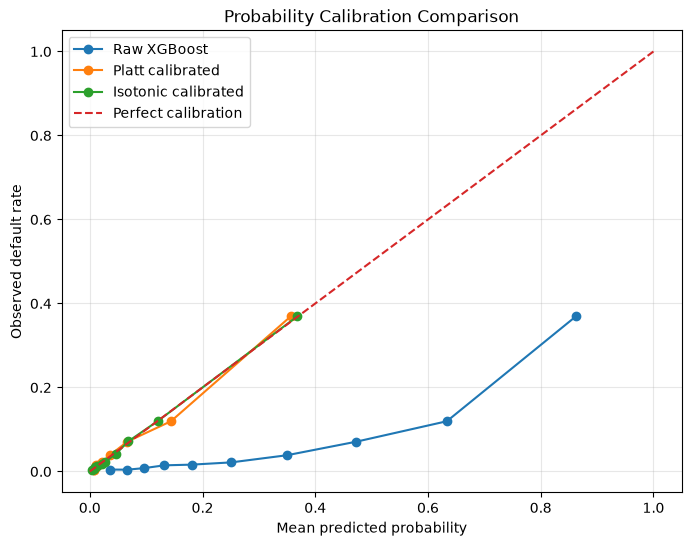

In [346]:
from sklearn.calibration import calibration_curve
import matplotlib.pyplot as plt

raw_true, raw_pred = calibration_curve(
    y_test,
    final_test_proba,
    n_bins=10,
    strategy="quantile"
)

platt_true, platt_pred = calibration_curve(
    y_test,
    test_proba_platt,
    n_bins=10,
    strategy="quantile"
)

iso_true, iso_pred = calibration_curve(
    y_test,
    test_proba_isotonic,
    n_bins=10,
    strategy="quantile"
)

plt.figure(figsize=(8, 6))

plt.plot(
    raw_pred,
    raw_true,
    marker="o",
    label="Raw XGBoost"
)

plt.plot(
    platt_pred,
    platt_true,
    marker="o",
    label="Platt calibrated"
)

plt.plot(
    iso_pred,
    iso_true,
    marker="o",
    label="Isotonic calibrated"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Perfect calibration"
)

plt.xlabel("Mean predicted probability")
plt.ylabel("Observed default rate")
plt.title("Probability Calibration Comparison")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## Calibration Method Selection Using OOF Predictions

Platt scaling and isotonic regression are compared using out-of-fold
predictions generated exclusively from the training set.

The untouched test set is not used to select the calibration method.

The calibration method with the lowest OOF Brier score is selected for
final evaluation on the test set.

In [348]:
from sklearn.metrics import brier_score_loss

# Calibrate the OOF predictions themselves
oof_proba_platt = platt_calibrator.predict_proba(
    monotonic_oof_proba.reshape(-1, 1)
)[:, 1]

oof_proba_isotonic = isotonic_calibrator.predict(
    monotonic_oof_proba
)

oof_calibration_results = pd.DataFrame([
    {
        "Model": "Raw Monotonic XGBoost",
        "Brier Score": brier_score_loss(
            y_train,
            monotonic_oof_proba
        )
    },
    {
        "Model": "Platt Calibrated",
        "Brier Score": brier_score_loss(
            y_train,
            oof_proba_platt
        )
    },
    {
        "Model": "Isotonic Calibrated",
        "Brier Score": brier_score_loss(
            y_train,
            oof_proba_isotonic
        )
    }
])

oof_calibration_results.sort_values("Brier Score")

,Model,Brier Score
2,Isotonic Calibrated,0.049331
1,Platt Calibrated,0.050017
0,Raw Monotonic XGBoost,0.136803


In [349]:
best_calibrator_name = (
    oof_calibration_results
    .sort_values("Brier Score")
    .iloc[0]["Model"]
)

print("Selected calibration method:", best_calibrator_name)

Selected calibration method: Isotonic Calibrated


In [350]:
best_calibrator_name = (
    oof_calibration_results
    .sort_values("Brier Score")
    .iloc[0]["Model"]
)

print("Selected calibration method:", best_calibrator_name)

Selected calibration method: Isotonic Calibrated


## Calibration Method Selection Using OOF Predictions

Platt scaling and isotonic regression are compared using out-of-fold
predictions generated exclusively from the training set.

The untouched test set is not used to select the calibration method.

The calibration method with the lowest OOF Brier score is selected for
final evaluation on the test set.

In [357]:
from sklearn.metrics import brier_score_loss

# Calibrate the OOF predictions themselves
oof_proba_platt = platt_calibrator.predict_proba(
    monotonic_oof_proba.reshape(-1, 1)
)[:, 1]

oof_proba_isotonic = isotonic_calibrator.predict(
    monotonic_oof_proba
)

oof_calibration_results = pd.DataFrame([
    {
        "Model": "Raw Monotonic XGBoost",
        "Brier Score": brier_score_loss(
            y_train,
            monotonic_oof_proba
        )
    },
    {
        "Model": "Platt Calibrated",
        "Brier Score": brier_score_loss(
            y_train,
            oof_proba_platt
        )
    },
    {
        "Model": "Isotonic Calibrated",
        "Brier Score": brier_score_loss(
            y_train,
            oof_proba_isotonic
        )
    }
])

oof_calibration_results.sort_values("Brier Score")

,Model,Brier Score
2,Isotonic Calibrated,0.049331
1,Platt Calibrated,0.050017
0,Raw Monotonic XGBoost,0.136803


In [359]:
best_calibrator_name = (
    oof_calibration_results
    .sort_values("Brier Score")
    .iloc[0]["Model"]
)

print("Selected calibration method:", best_calibrator_name)

Selected calibration method: Isotonic Calibrated


In [360]:
final_calibrated_test_proba = isotonic_calibrator.predict(
    final_test_proba
)

print(final_calibrated_test_proba[:10])

[0.01286089 0.00813752 0.01286089 0.01389766 0.02602422 0.06497696
 0.00813752 0.27212393 0.00451306 0.00864937]


## Operating Threshold Selection After Calibration

Calibration changes the probability scale, therefore the original threshold
of 0.40 cannot be reused automatically.

The operating threshold is selected using calibrated OOF predictions from
the training set.

The objective is to maintain high recall and minimize false negatives,
consistent with the credit-risk use case.

The test set is reserved for the final evaluation only.

In [361]:
from sklearn.metrics import precision_score, recall_score, f1_score

thresholds = np.arange(0.05, 0.96, 0.01)

threshold_results = []

for threshold in thresholds:

    y_pred = (
        oof_proba_isotonic >= threshold
    ).astype(int)

    threshold_results.append({
        "Threshold": threshold,
        "Precision": precision_score(
            y_train,
            y_pred,
            zero_division=0
        ),
        "Recall": recall_score(
            y_train,
            y_pred,
            zero_division=0
        ),
        "F1": f1_score(
            y_train,
            y_pred,
            zero_division=0
        )
    })

calibrated_threshold_results = pd.DataFrame(
    threshold_results
)

calibrated_threshold_results.head()

,Threshold,Precision,Recall,F1
0,0.05,0.180099,0.827453,0.295813
1,0.06,0.201168,0.790425,0.320712
2,0.07,0.211238,0.772846,0.331790
3,0.08,0.246618,0.715871,0.366854
4,0.09,0.265149,0.689565,0.383020


In [354]:
target_recall = 0.84

best_threshold_row = (
    calibrated_threshold_results
    .assign(
        Recall_Difference=lambda x:
        abs(x["Recall"] - target_recall)
    )
    .sort_values("Recall_Difference")
    .iloc[0]
)

best_threshold_row

Threshold            0.050000
Precision            0.180099
Recall               0.827453
F1                   0.295813
Recall_Difference    0.012547
Name: 0, dtype: float64

In [355]:
calibrated_threshold = best_threshold_row["Threshold"]

print("Selected calibrated threshold:",
      calibrated_threshold)

print("OOF Recall:",
      best_threshold_row["Recall"])

print("OOF Precision:",
      best_threshold_row["Precision"])

print("OOF F1:",
      best_threshold_row["F1"])

Selected calibrated threshold: 0.05
OOF Recall: 0.8274529360428874
OOF Precision: 0.18009877347226744
OOF F1: 0.295812626746596


In [362]:
final_calibrated_pred = (
    final_calibrated_test_proba >= calibrated_threshold
).astype(int)

In [363]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    roc_auc_score,
    average_precision_score
)

cm = confusion_matrix(
    y_test,
    final_calibrated_pred
)

tn, fp, fn, tp = cm.ravel()

final_calibrated_results = {
    "Accuracy": accuracy_score(
        y_test,
        final_calibrated_pred
    ),
    "Precision": precision_score(
        y_test,
        final_calibrated_pred,
        zero_division=0
    ),
    "Recall": recall_score(
        y_test,
        final_calibrated_pred,
        zero_division=0
    ),
    "F1": f1_score(
        y_test,
        final_calibrated_pred,
        zero_division=0
    ),
    "ROC-AUC": roc_auc_score(
        y_test,
        final_calibrated_test_proba
    ),
    "PR-AUC": average_precision_score(
        y_test,
        final_calibrated_test_proba
    ),
    "TP": tp,
    "TN": tn,
    "FP": fp,
    "FN": fn,
    "Threshold": calibrated_threshold
}

pd.DataFrame([final_calibrated_results])

,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC,TP,TN,FP,FN,Threshold
0,0.7371,0.182603,0.84389,0.30024,0.86766,0.389181,1692,20421,7574,313,0.05


In [364]:
from sklearn.metrics import brier_score_loss

raw_brier = brier_score_loss(
    y_test,
    final_test_proba
)

calibrated_brier = brier_score_loss(
    y_test,
    final_calibrated_test_proba
)

print("Raw Brier Score:", raw_brier)
print("Calibrated Brier Score:", calibrated_brier)

Raw Brier Score: 0.13708814978599548
Calibrated Brier Score: 0.049131814390420914


In [365]:
print(
    "Brier improvement:",
    raw_brier - calibrated_brier
)

Brier improvement: 0.08795633539557457


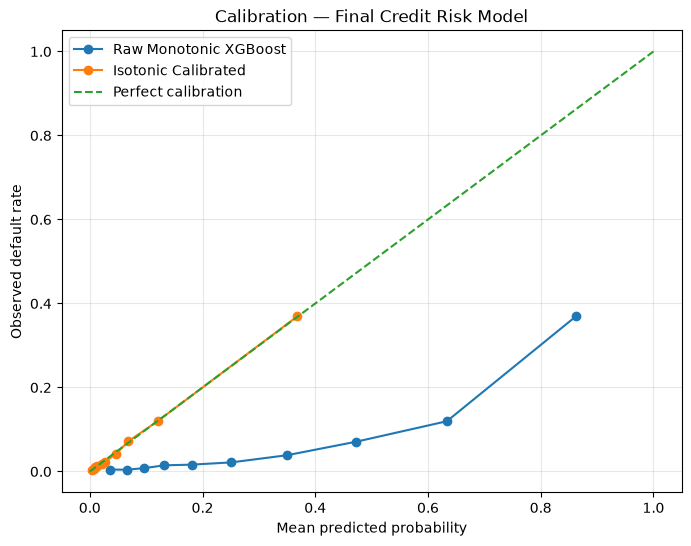

In [366]:
from sklearn.calibration import calibration_curve
import matplotlib.pyplot as plt

prob_true_raw, prob_pred_raw = calibration_curve(
    y_test,
    final_test_proba,
    n_bins=10,
    strategy="quantile"
)

prob_true_cal, prob_pred_cal = calibration_curve(
    y_test,
    final_calibrated_test_proba,
    n_bins=10,
    strategy="quantile"
)

plt.figure(figsize=(8, 6))

plt.plot(
    prob_pred_raw,
    prob_true_raw,
    marker="o",
    label="Raw Monotonic XGBoost"
)

plt.plot(
    prob_pred_cal,
    prob_true_cal,
    marker="o",
    label="Isotonic Calibrated"
)

plt.plot(
    [0, 1],
    [0, 1],
    "--",
    label="Perfect calibration"
)

plt.xlabel("Mean predicted probability")
plt.ylabel("Observed default rate")
plt.title("Calibration — Final Credit Risk Model")
plt.legend()
plt.grid(True, alpha=0.3)

plt.show()

## Final Model Packaging

The final credit-risk model consists of:

1. Ablated feature set excluding LogMonthlyIncome and IncomeCategory.
2. XGBoost with a monotonic constraint on MonthlyIncome.
3. Isotonic probability calibration.
4. Operating threshold selected using OOF predictions.

The untouched test set is used only for final performance reporting.

In [367]:
import joblib
import os

os.makedirs("Model", exist_ok=True)

joblib.dump(
    monotonic_ablation_pipeline,
    "Model/final_monotonic_xgb.pkl"
)

joblib.dump(
    isotonic_calibrator,
    "Model/isotonic_calibrator.pkl"
)

joblib.dump(
    float(calibrated_threshold),
    "Model/final_threshold.pkl"
)

print("Final model artifacts saved successfully.")

Final model artifacts saved successfully.


In [368]:
final_model_package = {
    "model": monotonic_ablation_pipeline,
    "calibrator": isotonic_calibrator,
    "threshold": float(calibrated_threshold),
    "feature_set": [
        col for col in X_train.columns
        if col not in [
            "LogMonthlyIncome",
            "IncomeCategory"
        ]
    ]
}

joblib.dump(
    final_model_package,
    "Model/final_credit_risk_model.pkl"
)

print("Complete final model package saved.")

Complete final model package saved.


In [369]:
loaded_package = joblib.load(
    "Model/final_credit_risk_model.pkl"
)

loaded_model = loaded_package["model"]
loaded_calibrator = loaded_package["calibrator"]
loaded_threshold = loaded_package["threshold"]

raw_probability = loaded_model.predict_proba(
    X_test.iloc[[0]]
)[:, 1]

calibrated_probability = loaded_calibrator.predict(
    raw_probability
)[0]

prediction = int(
    calibrated_probability >= loaded_threshold
)

print("Raw probability:", raw_probability[0])
print("Calibrated probability:", calibrated_probability)
print("Threshold:", loaded_threshold)
print("Prediction:", prediction)

Raw probability: 0.12404803
Calibrated probability: 0.012860892
Threshold: 0.05
Prediction: 0


In [370]:
income_values = [
    5000,
    10000,
    15000,
    20000,
    30000,
    50000,
    75000,
    100000
]

final_income_results = []

for income in income_values:

    borrower = X_test.iloc[[0]].copy()

    borrower["MonthlyIncome"] = income

    raw_prob = loaded_model.predict_proba(
        borrower
    )[:, 1][0]

    calibrated_prob = loaded_calibrator.predict(
        [raw_prob]
    )[0]

    final_income_results.append({
        "MonthlyIncome": income,
        "RawProbability": raw_prob,
        "CalibratedProbability": calibrated_prob,
        "Prediction": int(
            calibrated_prob >= loaded_threshold
        )
    })

final_income_results = pd.DataFrame(
    final_income_results
)

final_income_results

,MonthlyIncome,RawProbability,CalibratedProbability,Prediction
0,5000,0.140096,0.013898,0
1,10000,0.120215,0.012861,0
2,15000,0.095341,0.008649,0
3,20000,0.095341,0.008649,0
4,30000,0.095341,0.008649,0
5,50000,0.095341,0.008649,0
6,75000,0.095341,0.008649,0
7,100000,0.095341,0.008649,0


In [371]:
probabilities = (
    final_income_results["CalibratedProbability"]
    .values
)

differences = np.diff(probabilities)

print("Probability changes:", differences)

print(
    "Upward movements:",
    np.sum(differences > 1e-8)
)

print(
    "Largest upward movement:",
    max(0, differences.max())
)

Probability changes: [-0.00103677 -0.00421152  0.          0.          0.          0.
  0.        ]
Upward movements: 0
Largest upward movement: 0


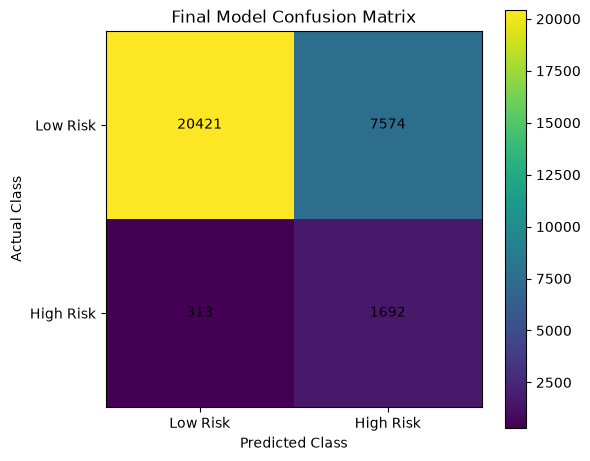

In [372]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt

cm = confusion_matrix(
    y_test,
    final_calibrated_pred
)

plt.figure(figsize=(6, 5))

plt.imshow(cm)

plt.title("Final Model Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

plt.xticks(
    [0, 1],
    ["Low Risk", "High Risk"]
)

plt.yticks(
    [0, 1],
    ["Low Risk", "High Risk"]
)

for i in range(2):
    for j in range(2):
        plt.text(
            j,
            i,
            cm[i, j],
            ha="center",
            va="center"
        )

plt.colorbar()
plt.tight_layout()
plt.show()

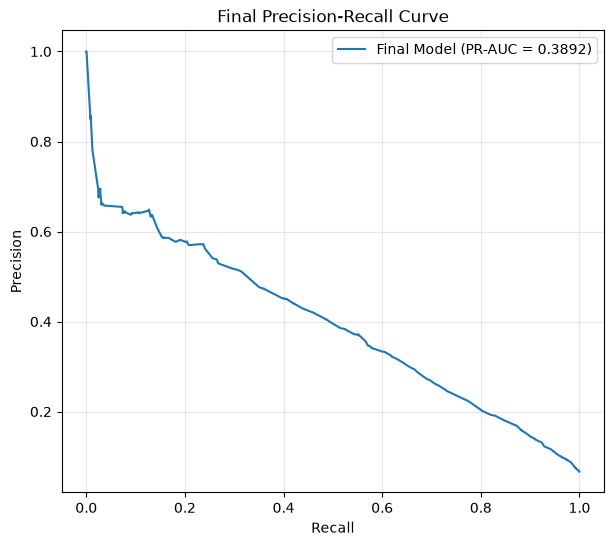

In [373]:
from sklearn.metrics import precision_recall_curve, average_precision_score

precision, recall, _ = precision_recall_curve(
    y_test,
    final_calibrated_test_proba
)

pr_auc = average_precision_score(
    y_test,
    final_calibrated_test_proba
)

plt.figure(figsize=(7, 6))

plt.plot(
    recall,
    precision,
    label=f"Final Model (PR-AUC = {pr_auc:.4f})"
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Final Precision-Recall Curve")
plt.legend()
plt.grid(True, alpha=0.3)

plt.show()

In [374]:
final_summary = pd.DataFrame([{
    "Model": "Final Monotonic XGBoost + Isotonic",
    "Threshold": calibrated_threshold,
    "Accuracy": accuracy_score(
        y_test,
        final_calibrated_pred
    ),
    "Precision": precision_score(
        y_test,
        final_calibrated_pred,
        zero_division=0
    ),
    "Recall": recall_score(
        y_test,
        final_calibrated_pred,
        zero_division=0
    ),
    "F1": f1_score(
        y_test,
        final_calibrated_pred,
        zero_division=0
    ),
    "ROC-AUC": roc_auc_score(
        y_test,
        final_calibrated_test_proba
    ),
    "PR-AUC": average_precision_score(
        y_test,
        final_calibrated_test_proba
    ),
    "Brier": brier_score_loss(
        y_test,
        final_calibrated_test_proba
    ),
    "TP": tp,
    "TN": tn,
    "FP": fp,
    "FN": fn
}])

final_summary

,Model,Threshold,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC,Brier,TP,TN,FP,FN
0,Final Monotonic XGBoost + Isotonic,0.05,0.7371,0.182603,0.84389,0.30024,0.86766,0.389181,0.049132,1692,20421,7574,313


In [375]:
import joblib
import os

os.makedirs("Model", exist_ok=True)

final_package = {
    "model": monotonic_ablation_pipeline,
    "calibrator": isotonic_calibrator,
    "threshold": float(calibrated_threshold),
    "removed_features": [
        "LogMonthlyIncome",
        "IncomeCategory"
    ]
}

joblib.dump(
    final_package,
    "Model/final_credit_risk_model.pkl"
)

print("Saved:", os.path.abspath(
    "Model/final_credit_risk_model.pkl"
))

Saved: c:\Users\HP\Desktop\CREDIT_RISK_ASSESSMENT\Notebooks\Model\final_credit_risk_model.pkl
